# 06: Task performance

*How reliably does the KG support biological inference?*

| Sub-metric | Definition | Quantification | Scoring |
|---|---|---|---|
| **Link prediction** | Discrimination of known drug-disease indication pairs from type-constrained random negatives | AUROC under Adamic-Adar, the pre-specified primary heuristic | Rescaled AUROC, (AUROC − 0.5) / 0.5, so the floor is 0 like the other two |
| **Neighbourhood retrieval** | Recovery of held-out disease-gene associations among top-ranked graph-proximity candidates | Recall@100 under leave-one-out for every disease with at least five known targets | Direct proportion |
| **Multi-hop reasoning** | Recovery of known mechanistic target genes as intermediate nodes on drug→gene→disease paths | Hits@100 over known (drug, gene, disease) triples scored by AA(drug, g) × AA(g, disease) | Direct proportion |

The dimension score is the equal-weighted mean of the three.

**Reported, not scored.** Common Neighbors and Jaccard beside Adamic-Adar, conditional Hits@100, and the embedding cross-check.

**Chance floors differ across the three sub-metrics.** AUROC is 0.5 at chance while Recall@100 and Hits@100 are 0, so averaging the raw values would let a graph with no link-prediction signal contribute a third of a point. Link prediction is therefore rescaled to (AUROC − 0.5) / 0.5 before the mean is taken, which is what `RESCALE_AUROC` controls.

**Conditional Hits@100 separates two failures that the unconditional figure merges.** A triple can miss because the intermediate gene is ranked badly or because it carries no score at all; only the first is a ranking failure, and the conditional form reports it alone.

**The embedding cross-check asks whether the ranking is a property of the graph or of Adamic-Adar.** It reruns all three tasks under a learned representation; agreement means the conclusion is structural rather than an artefact of one heuristic.

**Inputs:** `config/kgs.yaml` · `config/params.yaml` · KG edge and node files · `data/gold_standards/ctd/CTD_chem_gene_ixns.tsv.gz` · `data/gold_standards/ctd/CTD_curated_genes_diseases.tsv.gz`

**Outputs:** `results/{figures,tables}/06_task_performance/` · `results/checkpoints/06_task_performance.pkl`

Design notes and justifications: [`README.md`](README.md)

## Set-up
All graphs and node tables are loaded using the shared `src/` loading utilities and evaluated under identical conditions. The same random seed (`seed = 42`) and negative sampling strategies are used throughout.

In [1]:
# Pick up edits to src/ without restarting the kernel. Without this, editing a
# module after it has been imported leaves the kernel holding the old version,
# which surfaces as a confusing ImportError for a name that is plainly on disk.
try:
    get_ipython().run_line_magic('load_ext', 'autoreload')
    get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass                      # not running under IPython (headless runner, plain python)

from collections import defaultdict
from itertools import combinations
from pathlib import Path
import gc
import gzip
import hashlib
import json
import pickle
import sys
import time
import warnings
import zlib

warnings.filterwarnings('ignore')

# Locate the repo root from any depth, then make the package importable.
# (`pip install -e .` also works and makes this block a no-op.)
_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'config' / 'kgs.yaml').exists())
if str(_root / 'src') not in sys.path:
    sys.path.insert(0, str(_root / 'src'))

from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from biokgsuite.graph.graph_utils import build_graph, build_lookup_maps
from biokgsuite.graph.negative_sampling import generate_negatives
from biokgsuite.graph.scoring import SCORERS
from biokgsuite.io import Outputs, assert_full_panel, find_config, load_config, load_kg, require
from biokgsuite.stats.evaluation import compute_metrics
from biokgsuite.viz.dimension06 import (fig06_link_heatmap, fig06_link_pr,
                                        fig06_multihop, fig06_retrieval)
from biokgsuite.viz.style import KG_PALETTE, setup_style

setup_style()

In [2]:
# Config, and the results writer.
config = load_config(find_config(_root))
params = config['analysis_params']
BASE   = config['_base_dir']

# Every figure, table and checkpoint goes through `out`, as in notebooks 01-05.
# Three of this notebook's four figures used to save themselves from inline
# cells, so they never appeared in the results manifest and could not be redrawn
# without re-running the analysis.
out = Outputs('06_task_performance', BASE)

# Bootstrap CI and permutation test utilities
# Read from config, not declared here. params.yaml has carried n_bootstrap all
# along and only notebook 07 read it, so this notebook would not have followed
# a change to it.
N_BOOT   = require(params, 'n_bootstrap')
SEED     = require(params, 'random_seed')
BOOT_RNG = np.random.RandomState(SEED)


def _kg_rng(name: str, purpose: str) -> np.random.RandomState:
    """A generator keyed on the KG and on what the draw is for.

    A single generator consumed across the KG loop makes every draw depend on
    how many draws the graphs before it made, so adding a KG to config/kgs.yaml
    silently moves the splits, the negatives, the query samples and the
    bootstrap intervals of every KG after it, for a reason that has nothing to
    do with the graphs. Keyed this way, a graph's numbers are the same whether
    it is run alone or in a panel of six.

    Call once per (kg, purpose) and reuse the object; calling it again restarts
    the same sequence.
    """
    return np.random.RandomState(
        SEED + (zlib.crc32(f'{name}|{purpose}'.encode()) % 100_000))

def bootstrap_metric_ci(scores_arr, labels_arr, metric_fn, n_boot=N_BOOT,
                        rng=None, stratified=True):
    """Percentile bootstrap 95% CI for an arbitrary metric.

    Parameters
    ----------
    scores_arr : np.ndarray
    labels_arr : np.ndarray (binary)
    metric_fn  : callable(scores, labels) -> float
    stratified : bool — if True, resample positives and negatives separately
                 to preserve class ratio in every bootstrap sample.

    Returns
    -------
    (point, ci_lo, ci_hi) or (nan, nan, nan)
    """
    # Default is a FRESH generator, not the module-level BOOT_RNG. A shared
    # default is consumed in call order, which made every interval depend on how
    # many KGs were bootstrapped before it. Call sites pass a _kg_rng stream;
    # this default keeps an un-passed call panel-independent too.
    rng = np.random.RandomState(SEED) if rng is None else rng
    scores_arr = np.asarray(scores_arr, dtype=float)
    labels_arr = np.asarray(labels_arr, dtype=int)
    n = len(scores_arr)
    pos_idx = np.where(labels_arr == 1)[0]
    neg_idx = np.where(labels_arr == 0)[0]
    if len(pos_idx) < 2 or len(neg_idx) < 2:
        return np.nan, np.nan, np.nan

    boots = []
    for _ in range(n_boot):
        if stratified:
            bi_pos = rng.choice(pos_idx, size=len(pos_idx), replace=True)
            bi_neg = rng.choice(neg_idx, size=len(neg_idx), replace=True)
            bi = np.concatenate([bi_pos, bi_neg])
        else:
            bi = rng.randint(0, n, n)
        b_labels = labels_arr[bi]
        if b_labels.sum() == 0 or b_labels.sum() == len(b_labels):
            continue
        try:
            boots.append(metric_fn(scores_arr[bi], b_labels))
        except Exception:
            continue
    if len(boots) < 10:
        return np.nan, np.nan, np.nan
    point = metric_fn(scores_arr, labels_arr)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return float(point), float(lo), float(hi)

def permutation_test_auroc(scores_a, labels_a, scores_b, labels_b,
                           n_perm=1000, rng=None):
    """Two-sided permutation test for difference in AUROC between two KGs.

    Null hypothesis: the two sets of (scores, labels) come from systems
    with equal AUROC. We permute the assignment of score vectors to KGs
    and measure the fraction of permutations where |delta_AUROC| >= observed.

    Returns
    -------
    p_value : float
    """
    rng = np.random.RandomState(SEED) if rng is None else rng
    obs_a = roc_auc_score(labels_a, scores_a)
    obs_b = roc_auc_score(labels_b, scores_b)
    obs_diff = abs(obs_a - obs_b)

    # Pool scores and labels
    pooled_scores = np.concatenate([scores_a, scores_b])
    pooled_labels = np.concatenate([labels_a, labels_b])
    n_a = len(scores_a)
    n_total = len(pooled_scores)

    count = 0
    for _ in range(n_perm):
        perm = rng.permutation(n_total)
        pa_s, pa_l = pooled_scores[perm[:n_a]], pooled_labels[perm[:n_a]]
        pb_s, pb_l = pooled_scores[perm[n_a:]], pooled_labels[perm[n_a:]]
        # Skip degenerate splits
        if pa_l.sum() == 0 or pa_l.sum() == len(pa_l):
            continue
        if pb_l.sum() == 0 or pb_l.sum() == len(pb_l):
            continue
        try:
            d = abs(roc_auc_score(pa_l, pa_s) - roc_auc_score(pb_l, pb_s))
        except Exception:
            continue
        if d >= obs_diff:
            count += 1
    return count / n_perm

print(f'Bootstrap utilities loaded: N_BOOT={N_BOOT}, stratified resampling')

# A run that scores fewer graphs than config/kgs.yaml declares is a
# different experiment, not a smaller one, so it has to be asked for.
ALLOW_PARTIAL_PANEL = False


### Loading

In [5]:
# Free any KG/graph state left over from a previous notebook.
for _v in ('kgs', 'graphs', 'maps'):
    try:
        del globals()[_v]
    except KeyError:
        pass
gc.collect()

# Load KGs
KG_NAMES = list(config['knowledge_graphs'].keys())

kgs = {}
for name in KG_NAMES:
    try:
        kg, nodes = load_kg(name, config)
        kgs[name] = {'kg': kg, 'nodes': nodes}
        print(f'{name:12s}: {len(kg):>12,} edges  {len(nodes):>8,} nodes  '
              f'{kg["relation"].nunique():>4} relation types')
    except FileNotFoundError:
        print(f'{name:12s}: [NOT FOUND]')
    except Exception as e:
        print(f'{name:12s}: [ERROR] {e}')

LOADED = [n for n in KG_NAMES if n in kgs and config['knowledge_graphs'].get(n, {}).get('relations')]
print(f'\nLoaded: {LOADED}')
# Refuse to score a panel that is missing graphs.
#
# The broad `except` above keeps one unreadable graph from taking down the run,
# but the cost is that a run finding two of six completes, prints a dimension
# score and writes a checkpoint indistinguishable from a full one. Scores that
# intersect or normalise across the panel then differ from what a full run would
# give, silently. Set ALLOW_PARTIAL_PANEL in the config cell to score a subset
# deliberately; the reduced panel is recorded in the checkpoint either way.
PANEL = assert_full_panel(LOADED, config,
                          allow_partial=ALLOW_PARTIAL_PANEL,
                          notebook='06_task_performance')


primekg     : [NOT FOUND]


hetionet    :    2,250,197 edges    47,031 nodes    24 relation types
drkg        : [NOT FOUND]
openbilink  : [NOT FOUND]


biokg       :    2,067,998 edges   105,524 nodes    17 relation types
  matrix: keep_categories=all → retaining every typed node and edge
matrix      : [NOT FOUND]

Loaded: ['hetionet', 'biokg']


In [6]:
# Build graphs and lookup maps
graphs, maps = {}, {}
for name, data in kgs.items():
    G            = build_graph(data['kg'], data['nodes'])
    m            = build_lookup_maps(data['nodes'])
    m['node_id_map'] = dict(zip(data['nodes']['idx'], data['nodes']['id']))
    # id_to_idx bare-id lookup (WARNING PrimeKG IDs can collide across types).
    # Use uid_to_idx (type/id keyed) or filter by node_type_map for safe lookups.
    m['id_to_idx']   = dict(zip(data['nodes']['id'],  data['nodes']['idx']))
    if 'uid' in data['nodes'].columns:
        m['uid_to_idx'] = dict(zip(data['nodes']['uid'], data['nodes']['idx']))
    graphs[name] = G
    maps[name]   = m
    print(f'{name:12s}: {G.number_of_nodes():,} nodes  {G.number_of_edges():,} edges')

hetionet    : 47,031 nodes  2,107,709 edges


biokg       : 105,524 nodes  2,043,846 edges


In [7]:
# Per-KG entity type and relation config - read from config, not hardcoded
KG_CONFIG = {
    name: config['knowledge_graphs'][name]
    for name in LOADED
}

# Convenience accessors. Each returns a TUPLE of KG-internal labels, because a
# canonical type may map to several: BioKG carries diseases as both `Disease`
# (MeSH) and `GeneticDisorder` (OMIM), and load_config normalises every
# entity_types value to a tuple for exactly that reason. Every comparison against
# these must be a membership test, never `==`; comparing a pandas Series to a
# tuple raises, and comparing a scalar to one is silently always False.
def kg_drug_type(name):    return KG_CONFIG[name]['entity_types']['Drug']
def kg_disease_type(name): return KG_CONFIG[name]['entity_types']['Disease']
def kg_gene_type(name):    return KG_CONFIG[name]['entity_types'].get('Gene/Protein', ())

def kg_indication_rels(name):
    # Handles singular `relation` and plural `relations`, as the drug_target
    # accessor below already did.
    cfg = KG_CONFIG[name]['relations']['drug_disease']
    return list(cfg['relations']) if 'relations' in cfg else [cfg['relation']]

def kg_drug_target_rels(name):
    """Return list of drug-target relation names (handles singular 'relation'
    or plural 'relations' in config — whichever the KG uses)."""
    cfg = KG_CONFIG[name]['relations'].get('drug_target', {})
    if 'relations' in cfg:  # plural list (e.g. openbilink)
        return cfg['relations']
    if 'relation' in cfg:  # singular string (e.g. primekg, hetionet)
        return [cfg['relation']]
    return []

**Negative sampling protocol** (Kotnis and Nastase, 2017): Drug-disease indication pairs (`indication` + `off-label use` edges) form the positive set. A 90/10 train/test split is used; test edges are removed from the graph before scoring to prevent data leakage. Negatives are generated under three strategies of increasing difficulty:

| Strategy | Construction | Purpose |
|---|---|---|
| **Random** | Uniform random drug-disease pairs not in positive set | Upper-bound estimate; easy to discriminate |
| **Type-constrained** | Random pairs restricted to drug and disease node types | Removes trivial type-based discrimination |
| **Shared-target** | Drug-disease pairs sharing at least one protein target | Hardest; tests whether the KG can distinguish therapeutically similar but non-indicated pairs |


In [8]:
# Extract positive pairs, entity sets, and drug-target maps
kg_pos_pairs, kg_entity_sets, kg_drug_targets = {}, {}, {}

for name, data in kgs.items():
    kg, nodes = data['kg'], data['nodes']
    dt, dis_t, gt = kg_drug_type(name), kg_disease_type(name), kg_gene_type(name)

    # Positive drug-disease indication pairs (vectorized - avoids
    # .iterrows() over potentially millions of rows on Matrix)
    ind_edges = kg[kg['relation'].isin(kg_indication_rels(name))]
    if not ind_edges.empty:
        _xt = ind_edges['x_type'].to_numpy()
        _yt = ind_edges['y_type'].to_numpy()
        _xi = ind_edges['x_index'].to_numpy()
        _yi = ind_edges['y_index'].to_numpy()
        _fwd  = np.isin(_xt, dt)    & np.isin(_yt, dis_t)
        _rev  = np.isin(_xt, dis_t) & np.isin(_yt, dt)
        _keep = _fwd | _rev
        _drug = np.where(_fwd, _xi, _yi)
        _dis  = np.where(_fwd, _yi, _xi)
        pos_pairs = set(zip(_drug[_keep].tolist(), _dis[_keep].tolist()))
    else:
        pos_pairs = set()
    kg_pos_pairs[name] = list(pos_pairs)

    # Entity index sets
    kg_entity_sets[name] = {
        etype: set(nodes[nodes['type'].isin(t)]['idx'])
        for etype, t in [('drug', dt), ('disease', dis_t), ('gene', gt)]
        if t
    }

    # Drug-target map drug_idx -> set of gene_idx (vectorized).
    # Uses kg_drug_target_rels() which handles both singular and plural config.
    dtmap = defaultdict(set)
    dtrels = kg_drug_target_rels(name)
    if dtrels:
        _dtsub = kg[kg['relation'].isin(dtrels)]
        # Constrain to genuine drug-gene edges. Relation name alone is not
        # sufficient: MATRIX lists `interacts_with` and
        # `directly_physically_interacts_with` under BOTH drug_target and
        # drug_drug, so without a type check its drug-drug edges are read as
        # drug-target pairs and pollute the shared-target negative sampler.
        if not _dtsub.empty and gt:
            _xt = _dtsub['x_type'].to_numpy()
            _yt = _dtsub['y_type'].to_numpy()
            _xi = _dtsub['x_index'].to_numpy()
            _yi = _dtsub['y_index'].to_numpy()
            _is_fwd = np.isin(_xt, dt) & np.isin(_yt, gt)
            _is_rev = np.isin(_yt, dt) & np.isin(_xt, gt)
            _keep   = _is_fwd | _is_rev
            _n_drop = int((~_keep).sum())
            if _n_drop:
                print(f'{name:12s}: dropped {_n_drop:,} non drug-gene edges '
                      f'from the drug-target map (relation name matched, types did not)')
            _is_fwd, _xi, _yi = _is_fwd[_keep], _xi[_keep], _yi[_keep]
            _drug = np.where(_is_fwd, _xi, _yi).tolist()
            _gene = np.where(_is_fwd, _yi, _xi).tolist()
            for _d, _g in zip(_drug, _gene):
                dtmap[_d].add(_g)
    kg_drug_targets[name] = dtmap

    print(f'{name:12s}: {len(pos_pairs):,} indication pairs  '
          f'drugs={len(kg_entity_sets[name].get("drug", {})):,}  '
          f'diseases={len(kg_entity_sets[name].get("disease", {})):,}  '
          f'genes={len(kg_entity_sets[name].get("gene", {})):,}  '
          f'drugs-with-targets={len(dtmap):,}')

hetionet    : 755 indication pairs  drugs=1,552  diseases=137  genes=20,945  drugs-with-targets=1,389


biokg       : 66,867 indication pairs  drugs=8,805  diseases=9,490  genes=59,204  drugs-with-targets=6,845


In [9]:
# Train/test split and training graph construction
TRAIN_RATIO = require(params, 'train_ratio')

# Splits use _kg_rng (defined in the set-up cell) so they are panel-independent.

kg_splits, kg_graphs_train = {}, {}

for name in LOADED:
    pos   = kg_pos_pairs[name]
    idx   = _kg_rng(name, 'split').permutation(len(pos))
    split = int(TRAIN_RATIO * len(pos))
    train_pos = [pos[i] for i in idx[:split]]
    test_pos  = [pos[i] for i in idx[split:]]

    kg_splits[name] = {
        'train_pos':     train_pos,
        'test_pos':      test_pos,
        'train_pos_set': set(train_pos),
        'test_pos_set':  set(test_pos),
        'all_pos_set':   set(pos),
    }

    # Scale-aware G.copy() is fine for small KGs but each copy of Matrix's
    # ~30 GB graph would push 48 GB hosts into swap. For huge graphs use a
    # subgraph_view that hides test edges via a lazy edge filter , no copy.
    if graphs[name].number_of_nodes() > 1_000_000:
        test_edge_set = frozenset((min(d,dis), max(d,dis)) for d, dis in test_pos)
        # `_hidden=test_edge_set` binds the VALUE here. Closing over the loop
        # variable instead made every view share whichever set the loop ended on,
        # so a graph on this branch kept its own test edges in the training graph
        # and leaked the test set straight into link prediction. Only graphs above
        # the node threshold take this branch, so Hetionet and BioKG were never
        # affected; MATRIX is.
        G_train = nx.subgraph_view(
            graphs[name],
            filter_edge=lambda u, v, _hidden=test_edge_set:
                (min(u, v), max(u, v)) not in _hidden)
    else:
        G_train = graphs[name].copy()
        G_train.remove_edges_from([(d, dis) for d, dis in test_pos if G_train.has_edge(d, dis)])
    kg_graphs_train[name] = G_train
    print(f'{name:12s}: train={len(train_pos):,}  test={len(test_pos):,}  '
          f'graph edges={G_train.number_of_edges():,}')

hetionet    : train=679  test=76  graph edges=2,107,633


biokg       : train=60,180  test=6,687  graph edges=2,037,159


In [10]:
# Negative sampling per strategy
# require(), not .get(): the fallback here was neg_ratio=1 while params.yaml
# says 5, so a missing key would have quietly quintupled the positive rate.
NEG_RATIO  = require(params, 'neg_ratio')
STRATEGIES = list(require(params, 'neg_strategies'))
STRAT_LABELS = {'random': 'Random', 'type-constrained': 'Type-constrained', 'shared-target': 'Shared-target'}

kg_negatives = {}
for name in LOADED:
    sp, ents = kg_splits[name], kg_entity_sets[name]
    n_neg    = len(sp['test_pos']) * NEG_RATIO
    neg      = {
        strat: generate_negatives(
            sp['test_pos'], n_neg, strat,
            ents['drug'], ents['disease'],
            kg_drug_targets[name], maps[name]['node_name_map'],
            sp['all_pos_set'], _kg_rng(name, f'negatives|{strat}'))
        for strat in STRATEGIES
    }
    kg_negatives[name] = neg
    print(f'{name:12s}: ' + '  '.join(f'{s}={len(neg[s]):,}' for s in STRATEGIES))

hetionet    : random=380  type-constrained=380  shared-target=380


biokg       : random=33,435  type-constrained=33,435  shared-target=33,435


## 1. Link prediction

Predict whether a therapeutic relationship exists between a drug and a disease using three graph-proximity heuristics, Common Neighbors, Jaccard, and Adamic-Adar, evaluated under each negative-sampling strategy.

**Heuristics:**

| Heuristic | Formula | Intuition |
|---|---|---|
| **Common Neighbors** | $\|N(u) \cap N(v)\|$ | Pairs with many shared neighbours are more likely linked |
| **Jaccard** | $\|N(u) \cap N(v)\| / \|N(u) \cup N(v)\|$ | Normalises by neighbourhood size to reduce hub bias |
| **Adamic-Adar** | $\sum_{w \in N(u) \cap N(v)} 1 / \log\|N(w)\|$ | Down-weights shared neighbours that are high-degree hubs |

**Metrics:** AUROC and AUPRC measure ranking quality across all thresholds; MRR and Hits@10 measure rank position of true positives.

In [11]:
# Link prediction evaluation , with bootstrap 95% CIs
PRIMARY_HEURISTIC = 'Adamic-Adar'  # pre-specified; not selected post-hoc
ANCHOR_STRAT      = 'type-constrained'  # primary negative-sampling strategy
link_results = {}
link_raw     = {}  # store raw (scores, labels) arrays for bootstrap & permutation tests

for name in LOADED:
    G_train = kg_graphs_train[name]
    sp, neg = kg_splits[name], kg_negatives[name]

    print(f'\n{name}')
    print(f'  indication pairs={len(sp["all_pos_set"]):,}  '
          f'train={len(sp["train_pos"]):,}  test={len(sp["test_pos"]):,}')
    print(f'  {"Heuristic":<20s}  {"Neg. Strategy":<20s}  {"AUROC":>7s}  {"95% CI":>16s}  '
          f'{"AUPRC":>7s}  {"95% CI":>16s}')
    print('  ' + '-' * 96)

    for heuristic, scorer in SCORERS.items():
        for strat in STRATEGIES:
            if len(sp['test_pos']) == 0 or len(neg[strat]) == 0:
                continue
            pairs  = sp['test_pos'] + neg[strat]
            labels = np.array([1] * len(sp['test_pos']) + [0] * len(neg[strat]))
            if len(set(labels)) < 2:
                continue
            scores = np.array(scorer(G_train, pairs))
            m      = compute_metrics(scores, labels)
            m.update({'heuristic': heuristic, 'neg_strategy': strat})
            # The evaluation size travels with every result. Without it the
            # table reports Hetionet's AUROC beside BioKG's with nothing to show
            # that one rests on 76 test positives and the other on 6,687, which
            # is why their CI widths differ by roughly eightfold. A reader can
            # now recompute the precision of every number in the table.
            m.update({
                'n_pos_total': len(sp['all_pos_set']),
                'n_train_pos': len(sp['train_pos']),
                'n_test_pos':  len(sp['test_pos']),
                'n_neg':       len(neg[strat]),
                'n_eval':      len(pairs),
            })

            # Bootstrap CIs for AUROC and AUPRC
            # One bootstrap stream per (KG, heuristic, strategy). The default
            # rng=BOOT_RNG is a single generator consumed in loop order, so
            # every interval depended on how many draws the graphs before it
            # made and adding a KG moved the CIs of every KG after it. The
            # point estimates were never affected; the intervals were.
            _, auroc_lo, auroc_hi = bootstrap_metric_ci(
                scores, labels, lambda s, l: roc_auc_score(l, s),
                rng=_kg_rng(name, f'boot-auroc|{heuristic}|{strat}'))
            _, auprc_lo, auprc_hi = bootstrap_metric_ci(
                scores, labels, lambda s, l: average_precision_score(l, s),
                rng=_kg_rng(name, f'boot-auprc|{heuristic}|{strat}'))
            m['auroc_ci_lo'] = auroc_lo
            m['auroc_ci_hi'] = auroc_hi
            m['auprc_ci_lo'] = auprc_lo
            m['auprc_ci_hi'] = auprc_hi

            link_results[(name, heuristic, strat)] = m
            link_raw[(name, heuristic, strat)]     = (scores, labels)

            print(f'  {heuristic:<20s}  {strat:<20s}  {m["auroc"]:7.4f}  '
                  f'[{auroc_lo:.4f}, {auroc_hi:.4f}]  '
                  f'{m["auprc"]:7.4f}  [{auprc_lo:.4f}, {auprc_hi:.4f}]')



hetionet
  indication pairs=755  train=679  test=76
  Heuristic             Neg. Strategy           AUROC            95% CI    AUPRC            95% CI
  ------------------------------------------------------------------------------------------------


  Common Neighbors      random                 0.9089  [0.8719, 0.9430]   0.7203  [0.6401, 0.8001]


  Common Neighbors      type-constrained       0.8941  [0.8532, 0.9311]   0.5813  [0.4935, 0.6948]


  Common Neighbors      shared-target          0.8252  [0.7741, 0.8666]   0.4644  [0.3790, 0.5807]


  Jaccard               random                 0.8982  [0.8582, 0.9338]   0.6652  [0.5711, 0.7726]


  Jaccard               type-constrained       0.8879  [0.8500, 0.9265]   0.6136  [0.5177, 0.7151]


... (9 outputs left out)

  Jaccard               shared-target          0.8838  [0.8791, 0.8891]   0.7220  [0.7117, 0.7328]


  Adamic-Adar           random                 0.9092  [0.9048, 0.9140]   0.8140  [0.8064, 0.8225]


  Adamic-Adar           type-constrained       0.9089  [0.9042, 0.9133]   0.8113  [0.8022, 0.8198]


  Adamic-Adar           shared-target          0.8839  [0.8787, 0.8887]   0.7274  [0.7179, 0.7373]


In [12]:
# Link prediction CI summary table (primary heuristic, type-constrained)
# n_test and the CI width are shown next to every estimate. The width is the
# honest summary of how much the graphs can be told apart: a 0.0757-wide
# interval and a 0.0096-wide one do not support the same claims.
print(f'\n{"KG":12s}  {"n_test":>7s}  {"AUROC":>7s}  {"95% CI":>16s}  {"width":>7s}  '
      f'{"AUPRC":>7s}  {"95% CI":>16s}')
print('-' * 86)
for name in LOADED:
    r = link_results.get((name, PRIMARY_HEURISTIC, ANCHOR_STRAT), {})
    if r:
        print(f'{name:12s}  {r["n_test_pos"]:7,d}  '
              f'{r["auroc"]:7.4f}  [{r["auroc_ci_lo"]:.4f}, {r["auroc_ci_hi"]:.4f}]  '
              f'{r["auroc_ci_hi"] - r["auroc_ci_lo"]:7.4f}  '
              f'{r["auprc"]:7.4f}  [{r["auprc_ci_lo"]:.4f}, {r["auprc_ci_hi"]:.4f}]')

# Pairwise permutation tests (Bonferroni-corrected)
n_pairs = len(list(combinations(LOADED, 2)))  # 15 for 6 KGs

print(f'\nPairwise permutation test for AUROC difference ({PRIMARY_HEURISTIC}, {ANCHOR_STRAT})')
print(f'Bonferroni correction for {n_pairs} comparisons (alpha=0.05 → threshold={0.05/n_pairs:.4f})\n')

perm_pvals = {}
for kg_a, kg_b in combinations(LOADED, 2):
    raw_a = link_raw.get((kg_a, PRIMARY_HEURISTIC, ANCHOR_STRAT))
    raw_b = link_raw.get((kg_b, PRIMARY_HEURISTIC, ANCHOR_STRAT))
    if raw_a is None or raw_b is None:
        perm_pvals[(kg_a, kg_b)] = np.nan
        continue
    # Keyed on the unordered pair, so a comparison gives the same p-value
    # wherever the two graphs sit in LOADED.
    p = permutation_test_auroc(raw_a[0], raw_a[1], raw_b[0], raw_b[1],
                               n_perm=1000,
                               rng=_kg_rng('|'.join(sorted((kg_a, kg_b))),
                                           'permtest'))
    p_corr = min(p * n_pairs, 1.0)  # Bonferroni
    perm_pvals[(kg_a, kg_b)] = p_corr
    sig = '***' if p_corr < 0.001 else '**' if p_corr < 0.01 else '*' if p_corr < 0.05 else 'n.s.'
    auroc_a = link_results[(kg_a, PRIMARY_HEURISTIC, ANCHOR_STRAT)]['auroc']
    auroc_b = link_results[(kg_b, PRIMARY_HEURISTIC, ANCHOR_STRAT)]['auroc']
    print(f'  {kg_a:12s} vs {kg_b:12s}  '
          f'ΔAUROC={auroc_a - auroc_b:+.4f}  '
          f'p_bonf={p_corr:.4f}  {sig}')

# Build p-value matrix for checkpoint
pval_matrix = pd.DataFrame(np.nan, index=LOADED, columns=LOADED)
for (a, b), p in perm_pvals.items():
    pval_matrix.loc[a, b] = p
    pval_matrix.loc[b, a] = p
for name in LOADED:
    pval_matrix.loc[name, name] = 1.0

print('\nBonferroni-corrected p-value matrix:')
print(pval_matrix.round(4).to_string())



KG             n_test    AUROC            95% CI    width    AUPRC            95% CI
--------------------------------------------------------------------------------------
hetionet           76   0.8984  [0.8562, 0.9330]   0.0768   0.6053  [0.5123, 0.7220]
biokg           6,687   0.9089  [0.9042, 0.9133]   0.0091   0.8113  [0.8022, 0.8198]

Pairwise permutation test for AUROC difference (Adamic-Adar, type-constrained)
Bonferroni correction for 1 comparisons (alpha=0.05 → threshold=0.0500)



  hetionet     vs biokg         ΔAUROC=-0.0104  p_bonf=0.6390  n.s.

Bonferroni-corrected p-value matrix:
          hetionet  biokg
hetionet     1.000  0.639
biokg        0.639  1.000


  → Saved: link_prediction_pr.pdf / .png  (300 dpi)


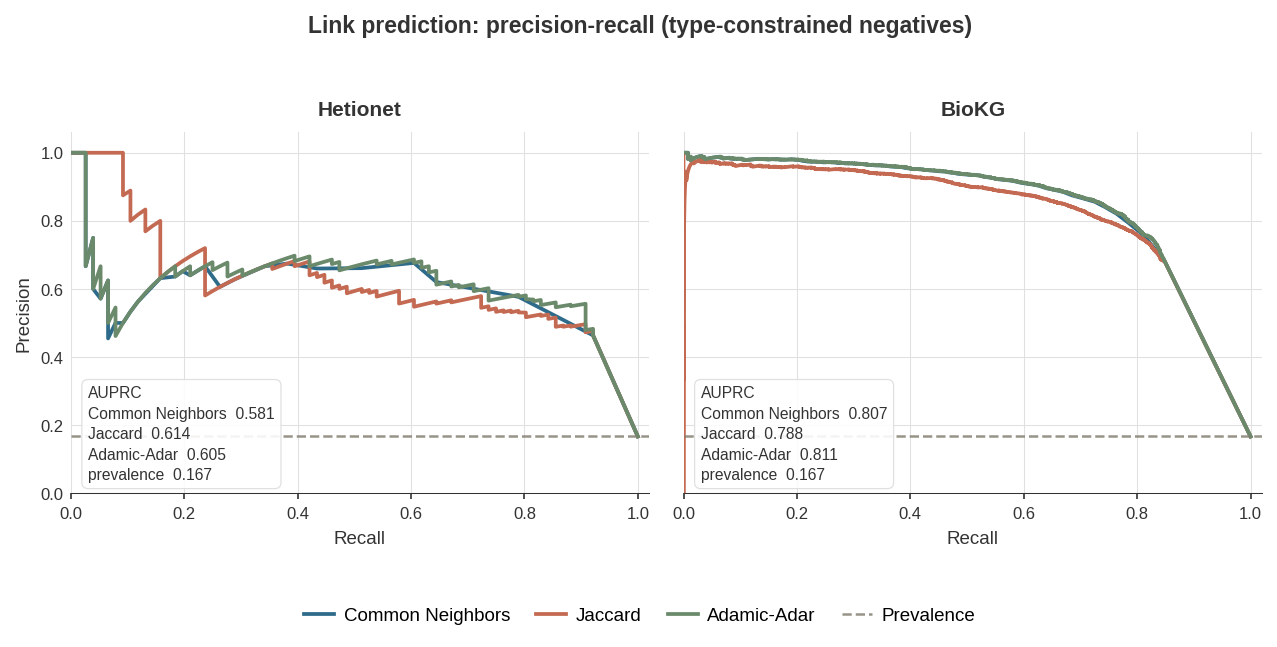

In [13]:
# Precision-recall curves, built from the SAME scores the AUPRC was computed
# from. This cell used to call SCORERS[heuristic](G_train, pairs) again for every
# KG and heuristic, duplicating the most expensive work in the notebook and
# leaving the drawn curve free to drift from the number labelling it. The scores
# are already in `link_raw`.
pr_curves = {}
for name in LOADED:
    sp, neg = kg_splits[name], kg_negatives[name]
    n_pos, n_neg = len(sp['test_pos']), len(neg[ANCHOR_STRAT])
    if not n_pos or not n_neg:
        continue
    curves = {}
    for heuristic in SCORERS:
        key = (name, heuristic, ANCHOR_STRAT)
        if key not in link_raw:
            continue
        scores, labels = link_raw[key]
        prec, rec, _ = precision_recall_curve(labels, scores)
        curves[heuristic] = (rec, prec, link_results[key]['auprc'])
    pr_curves[name] = {'baseline': n_pos / (n_pos + n_neg), 'curves': curves}

out.figure(fig06_link_pr(pr_curves, ANCHOR_STRAT), 'link_prediction_pr');


## 2. Neighbourhood retrieval

Given a disease, rank all candidate genes/proteins by their likelihood of being therapeutic targets. This tests whether the KG's network structure encodes disease-gene associations beyond what is explicitly labelled.

**Protocol.** Leave-one-out evaluation, for each disease with $\geq 5$ known gene targets, one target is held out and ranked against the full pool of candidate genes using Adamic-Adar. **Recall@K** is the fraction of held-out targets recovered in the top K, reported for K = 10, 50, 100. **MRR** (mean reciprocal rank) summarises the average rank position.

A random baseline would achieve Recall@10 $\approx 10 / N_{\text{genes}} \approx 0.04\%$, so values above 1% represent meaningful enrichment.

In [14]:
# Build disease-target ground truth for each KG using entity-type filtering
kg_disease_targets, kg_gene_lists = {}, {}
kg_disease_gene_rels = {}

for name, data in kgs.items():
    kg, nodes = data['kg'], data['nodes']
    dt, dis_t, gt = kg_drug_type(name), kg_disease_type(name), kg_gene_type(name)

    dg_edges = kg[
        (kg['x_type'].isin(dis_t) & kg['y_type'].isin(gt)) |
        (kg['x_type'].isin(gt)    & kg['y_type'].isin(dis_t))
    ]
    dis_tgts = defaultdict(set)
    for _, row in dg_edges.iterrows():
        if row['x_type'] in dis_t:
            dis_tgts[row['x_index']].add(row['y_index'])
        else:
            dis_tgts[row['y_index']].add(row['x_index'])

    eligible = {d: t for d, t in dis_tgts.items() if len(t) >= 5}
    gene_list = sorted(kg_entity_sets[name].get('gene', set()))

    kg_disease_targets[name] = eligible
    kg_gene_lists[name]      = gene_list
    # Disease-gene edges are selected by entity type, not by relation name, so
    # the relation vocabulary behind this metric appears nowhere in config. A
    # scorer that works on triples rather than on the collapsed graph needs it.
    kg_disease_gene_rels[name] = sorted(dg_edges['relation'].astype(str).unique())
    print(f'{name:12s}: diseases with >=5 targets={len(eligible):,}  candidate gene pool={len(gene_list):,}')

hetionet    : diseases with >=5 targets=121  candidate gene pool=20,945


biokg       : diseases with >=5 targets=2,482  candidate gene pool=59,204


In [15]:
# Free per-KG edge DataFrames
for _name in list(kgs):
    kgs[_name].pop('kg', None)
print('Released kgs[*][\'kg\'] DataFrames.')

Released kgs[*]['kg'] DataFrames.


In [16]:
# How many disease queries the retrieval metric is estimated from. Was a bare
# constant here, so the size of the evaluation did not appear in config.
N_EVAL = require(params, 'n_eval_queries')
# Pool-normalised cut. Recall@100 out of 20,945 candidates and Recall@100 out of
# 59,204 are not the same question: the second is a top-0.17% cut against a
# top-0.48% one, so a fixed K quietly asks the bigger graph for more. K_FRAC
# fixes the percentile instead, and both are reported.
K_FRAC = require(params, 'k_fraction')
target_results = {}

for name in LOADED:
    G            = graphs[name]
    eligible     = kg_disease_targets[name]
    gene_list    = kg_gene_lists[name]

    if not eligible or not gene_list:
        # NA, not 0.0. A graph with no eligible disease was never asked the
        # question, and 0.0 says it was asked and retrieved nothing. Scored
        # below as unavailable rather than as a floor result.
        target_results[name] = {
            'recall@10': np.nan, 'recall@50': np.nan, 'recall@100': np.nan,
            'mrr': np.nan, 'mean_rank': np.nan, 'median_rank': np.nan,
            'recall@frac': np.nan, 'k_fraction': K_FRAC,
            'k_norm': max(1, int(np.ceil(K_FRAC * len(gene_list)))),
            'n_eligible': len(eligible), 'n_requested': N_EVAL, 'n_drawn': 0,
            'n_evaluated': 0, 'ranks': np.array([]), 'pool_size': len(gene_list),
        }
        print(f'{name:12s}: no eligible diseases or genes — skipping neighbourhood retrieval')
        continue

    _rng = _kg_rng(name, 'retrieval')
    # sorted(), not list(): `eligible` is built by iterating an edge table into a
    # defaultdict, so its key order is an artefact of that pass. Pin it before
    # sampling or the query set is not reproducible across processes.
    _elig = sorted(eligible.keys())
    n_draw = min(N_EVAL, len(_elig))
    if n_draw < N_EVAL:
        # Said out loud. config/params.yaml asks for N_EVAL queries and this
        # graph cannot supply them, so the config otherwise states an evaluation
        # size the run did not perform. Hetionet has 121 eligible diseases out
        # of 134 in total, so the cap has never bound for it.
        print(f'{name:12s}: NOTE n_eval_queries={N_EVAL} does not bind, '
              f'only {len(_elig):,} diseases have >=5 targets; drawing {n_draw:,}')
    eval_diseases = _rng.choice(_elig, size=n_draw, replace=False)

    # Precompute inverse log-degree for Adamic-Adar
    inv_log_deg = {n: (1.0 / np.log(G.degree(n)) if G.degree(n) > 1 else 0.0) for n in G.nodes()}

    k_norm = max(1, int(np.ceil(K_FRAC * len(gene_list))))
    ranks, r10, r50, r100 = [], [], [], []
    # The exact questions asked, so a different scorer can be given the same
    # ones. An embedding cannot hide an edge at scoring time the way this loop
    # does, so it has to train with these pairs already removed.
    asked = []

    for i, disease in enumerate(eval_diseases):
        targets    = list(eligible[disease])
        held_out   = _rng.choice(targets)
        remaining  = set(targets) - {held_out}

        had_edge  = G.has_edge(disease, held_out)
        edge_data = G.edges[disease, held_out] if had_edge else None
        if had_edge: G.remove_edge(disease, held_out)

        dis_nbrs   = set(G.neighbors(disease))
        candidates = [g for g in gene_list if g not in remaining]
        scores     = np.zeros(len(candidates))
        for j, gene in enumerate(candidates):
            if G.has_node(gene):
                scores[j] = sum(inv_log_deg[w] for w in dis_nbrs & set(G.neighbors(gene)))

        if had_edge: G.add_edge(disease, held_out, **(edge_data or {}))

        asked.append((int(disease), int(held_out)))
        if held_out in candidates:
            held_idx = candidates.index(held_out)
            rank     = int(np.sum(scores >= scores[held_idx]))  # 1-indexed, ties conservative
            ranks.append(rank)
            r10.append(1 if rank <= 10  else 0)
            r50.append(1 if rank <= 50  else 0)
            r100.append(1 if rank <= 100 else 0)

        if (i + 1) % 100 == 0:
            print(f'  {name}: {i+1}/{len(eval_diseases)} evaluated...')

    ranks = np.array(ranks)
    _mrr  = float(np.mean(1.0 / ranks)) if len(ranks) else np.nan
    target_results[name] = {
        'recall@10':   np.mean(r10)  if r10  else np.nan,
        'recall@50':   np.mean(r50)  if r50  else np.nan,
        'recall@100':  np.mean(r100) if r100 else np.nan,
        'mrr':         _mrr,
        'mean_rank':   float(np.mean(ranks))   if len(ranks) else np.nan,
        'median_rank': float(np.median(ranks)) if len(ranks) else np.nan,
        # n_eligible is how many diseases could have been asked, n_requested
        # what the config asked for, n_drawn what was sampled, n_evaluated how
        # many produced a usable rank. Recall@100 is a mean over n_evaluated,
        # and that is the number its precision depends on.
        # Pool-normalised recall, from the same rank vector so it costs nothing
        # extra. The dimension score uses this; recall@100 stays in the table
        # because it is the figure the literature reports.
        'queries':     asked,
        'recall@frac': float(np.mean(ranks <= k_norm)) if len(ranks) else np.nan,
        'k_fraction':  K_FRAC,
        'k_norm':      k_norm,
        'n_eligible':  len(eligible),
        'n_requested': N_EVAL,
        'n_drawn':     len(eval_diseases),
        'n_evaluated': len(ranks),
        'ranks':       ranks,
        'pool_size':   len(gene_list),
    }
    print(f'{name:12s}: Recall@10={target_results[name]["recall@10"]:.3f}  '
          f'@50={target_results[name]["recall@50"]:.3f}  '
          f'@100={target_results[name]["recall@100"]:.3f}  MRR={_mrr:.4f}  '
          f'median rank={target_results[name]["median_rank"]:.0f}/{len(gene_list):,}  '
          f'(n={len(ranks):,} of {len(eval_diseases):,} drawn)')
    print(f'{"":12s}  Recall@{k_norm} = '
          f'{target_results[name]["recall@frac"]:.4f}  '
          f'(top {K_FRAC:.1%} of the {len(gene_list):,}-gene pool)')

hetionet    : NOTE n_eval_queries=300 does not bind, only 121 diseases have >=5 targets; drawing 121


  hetionet: 100/121 evaluated...


hetionet    : Recall@10=0.041  @50=0.099  @100=0.140  MRR=0.0168  median rank=1603/20,945  (n=121 of 121 drawn)
              Recall@105 = 0.1488  (top 0.5% of the 20,945-gene pool)


  biokg: 100/300 evaluated...


  biokg: 200/300 evaluated...


  biokg: 300/300 evaluated...
biokg       : Recall@10=0.097  @50=0.120  @100=0.147  MRR=0.0830  median rank=59190/59,204  (n=300 of 300 drawn)
              Recall@297 = 0.1733  (top 0.5% of the 59,204-gene pool)


In [17]:
# Bootstrap 95% CIs for neighbourhood retrieval (Recall@100)
nbhd_ci = {}
nbhd_frac_ci = {}   # pool-normalised cut; this is what the composite uses
print(f'{"KG":12s}  {"Recall@100":>10s}  {"95% CI":>16s}')
print('-' * 44)
for name in LOADED:
    ranks = target_results[name]['ranks']
    if len(ranks) < 10:
        nbhd_ci[name] = (target_results[name]['recall@100'], np.nan, np.nan)
        nbhd_frac_ci[name] = (target_results[name]['recall@frac'], np.nan, np.nan)
        continue
    # Bootstrap resample rank vectors, recompute Recall@100
    # Per-KG stream, for the reason given at the link-prediction bootstrap.
    # One resample index set, both cuts. Drawing separately would give the two
    # metrics independent noise when they come from the same rank vector.
    _brng = _kg_rng(name, 'boot-nbhd')
    _k = target_results[name]['k_norm']
    boots, boots_f = [], []
    for _ in range(N_BOOT):
        bi = _brng.choice(len(ranks), size=len(ranks), replace=True)
        boots.append(np.mean(ranks[bi] <= 100))
        boots_f.append(np.mean(ranks[bi] <= _k))
    point = np.mean(ranks <= 100)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    nbhd_ci[name] = (float(point), float(lo), float(hi))
    _fp = np.mean(ranks <= _k)
    _flo, _fhi = np.percentile(boots_f, [2.5, 97.5])
    nbhd_frac_ci[name] = (float(_fp), float(_flo), float(_fhi))
    print(f'{name:12s}  {point:10.4f}  [{lo:.4f}, {hi:.4f}]')


KG            Recall@100            95% CI
--------------------------------------------
hetionet          0.1405  [0.0826, 0.2066]
biokg             0.1467  [0.1100, 0.1900]


  → Saved: neighbourhood_retrieval.pdf / .png  (300 dpi)


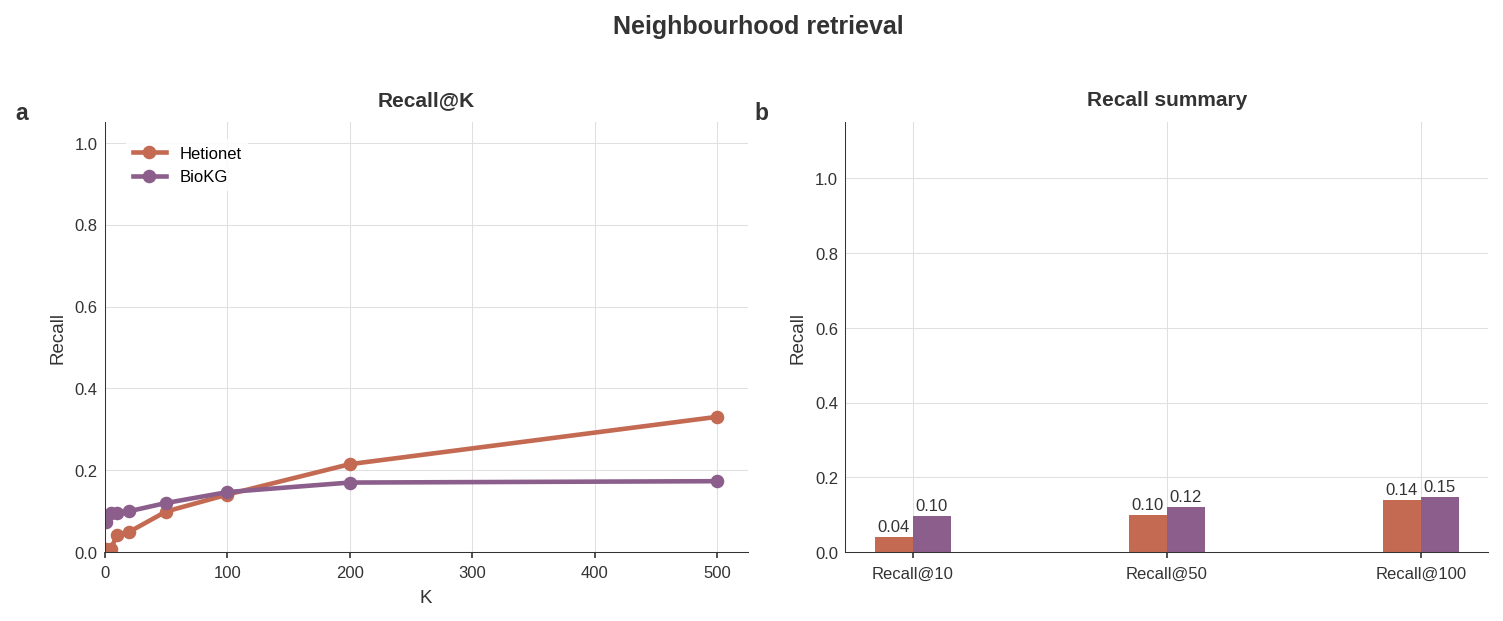

In [18]:
# Neighbourhood retrieval: Recall@K curves and the summary bars.
out.figure(fig06_retrieval(target_results), 'neighbourhood_retrieval');


## 3. Multi-hop reasoning

Given a known (drug, disease) therapeutic pair with a known mechanistic target gene, can the graph structure identify the correct target as the most plausible intermediate node?

**Gold standard construction.** Drug→gene→disease triplets are constructed from two CTD (Comparative Toxicogenomics Database; Davis et al., 2025) curated datasets:
- **CTD chemical-gene interactions**, curated from primary literature with PubMed evidence
- **CTD gene-disease associations**, curated gene→disease links with direct evidence (marker/mechanism or therapeutic)

These are fully external to the three benchmark KGs. For each chemical with a curated gene interaction, and each gene with a curated disease association, we obtain a validated (drug, gene, disease) chain. Triplets are filtered to entities resolvable in each KG.

**Protocol.** For each (drug, target, disease) triplet:
1. Remove the drug→disease indication edge (prevent leakage).
2. Score every candidate gene $g$ in the KG's gene pool as a potential intermediate:
$$\text{score}(g) = \text{AA}(\text{drug}, g) \times \text{AA}(g, \text{disease})$$
3. Rank all candidate genes by score and record the rank of the **known target**.

**Metrics:** Hits@100 (scored sub-metric), plus MRR and Hits@10 for characterisation.

**Sampling.** Up to 500 triplets per KG are sampled to keep runtime tractable.

> Davis, A.P. et al. Comparative Toxicogenomics Database's 20th anniversary: update 2025. *Nucleic Acids Res.* **53**, D1328 (2025).

In [19]:
# Build CTD-based multi-hop gold standard

# Load CTD chemical-gene interactions (human only)
ctd_cg_rows = []
# The multi-hop benchmark is the one part of this notebook needing data the
# repository does not carry. Say precisely what is missing rather than surfacing
# a bare FileNotFoundError on whichever file happens to be opened first.
_GS = BASE / 'data' / 'gold_standards'
_required = {
    'ctd/CTD_chem_gene_ixns.tsv.gz':         'bash tools/fetch_ctd.sh',
    'ctd/CTD_curated_genes_diseases.tsv.gz': 'bash tools/fetch_ctd.sh',
    'bridges/mesh_to_doid.csv':                  'python tools/build_gold_standard_aux.py',
    'bridges/drugbank_drugs.csv':                'python tools/build_gold_standard_aux.py',
}
_missing = {f: how for f, how in _required.items() if not (_GS / f).exists()}
if _missing:
    raise FileNotFoundError(
        'Multi-hop reasoning needs files not present in this checkout:\n'
        + '\n'.join(f'  data/gold_standards/{f}\n      -> {how}'
                     for f, how in _missing.items())
        + '\n\nctdbase.org is outside the egress allowlist on the analysis container'
          '\nand the desktop sandbox, so fetch_ctd.sh must run on an unrestricted'
          '\nnetwork with the files copied across. Link prediction and neighbourhood'
          '\nretrieval need none of this and have already run above; only the third'
          '\nsub-metric and the dimension score are blocked.')

with gzip.open(_GS / 'ctd' / 'CTD_chem_gene_ixns.tsv.gz', 'rt') as f:
    for line in f:
        if line.startswith('#'):
            continue
        parts = line.strip().split('\t')
        if len(parts) >= 7 and parts[6] == 'Homo sapiens':
            ctd_cg_rows.append({
                'chem_name':  parts[0].lower(),
                'chem_id':    parts[1],  # MESH ID
                'gene_symbol': parts[3],
                'gene_id':    int(parts[4]),  # NCBI gene ID
            })
ctd_cg = pd.DataFrame(ctd_cg_rows).drop_duplicates(subset=['chem_name', 'gene_id'])
print(f'CTD chem-gene (human, deduplicated): {len(ctd_cg):,} pairs  '
      f'({ctd_cg["chem_name"].nunique():,} chemicals, {ctd_cg["gene_id"].nunique():,} genes)')

# Load CTD gene-disease associations (direct evidence only)
ctd_gd_rows = []
with gzip.open(_GS / 'ctd' / 'CTD_curated_genes_diseases.tsv.gz', 'rt') as f:
    for line in f:
        if line.startswith('#'):
            continue
        parts = line.strip().split('\t')
        if len(parts) >= 5 and parts[4] in ('marker/mechanism', 'therapeutic'):
            ctd_gd_rows.append({
                'gene_symbol': parts[0],
                'gene_id':     int(parts[1]),
                'disease_name': parts[2].lower(),
                'disease_id':  parts[3],  # MESHxxx or OMIMxxx
            })
ctd_gd = pd.DataFrame(ctd_gd_rows).drop_duplicates(subset=['gene_id', 'disease_id'])
print(f'CTD gene-disease (direct evidence):  {len(ctd_gd):,} pairs  '
      f'({ctd_gd["gene_id"].nunique():,} genes, {ctd_gd["disease_id"].nunique():,} diseases)')

# Join chem → gene → disease triplets
ctd_triplets = ctd_cg.merge(ctd_gd, on='gene_id', suffixes=('_cg', '_gd'))
print(f'CTD triplets (chem→gene→disease):    {len(ctd_triplets):,} '
      f'({ctd_triplets["chem_name"].nunique():,} drugs, '
      f'{ctd_triplets["gene_id"].nunique():,} genes, '
      f'{ctd_triplets["disease_id"].nunique():,} diseases)')

CTD chem-gene (human, deduplicated): 829,489 pairs  (11,103 chemicals, 28,629 genes)
CTD gene-disease (direct evidence):  33,995 pairs  (9,130 genes, 5,844 diseases)


CTD triplets (chem→gene→disease):    4,760,182 (10,976 drugs, 8,743 genes, 5,827 diseases)


In [20]:

# Multi-hop resolve CTD triplets to KG node indices
N_MULTIHOP = 500  # max triplets sampled per KG

# Load MESH→DOID mapping once (used for ID-based disease resolution)
_m2d_raw = pd.read_csv(BASE / 'data/gold_standards/bridges/mesh_to_doid.csv', on_bad_lines='skip')
_m2d_raw['mesh_clean'] = _m2d_raw['mesh_id'].str.split(' ').str[0]
MESH_TO_DOID = dict(zip(_m2d_raw['mesh_clean'], _m2d_raw['doid']))  # 'MESHD*' → 'DOID*'

# Load DrugBank names once
# Any KG whose nodes carry a drugbank_id column gets human-readable drug names
# injected into its lookup automatically (no KG-specific hardcoding needed).
_db_names_df = pd.read_csv(BASE / 'data/gold_standards/bridges/drugbank_drugs.csv',
                           usecols=['drugbank_id', 'name'])
_DRUGBANK_NAME_MAP = dict(zip(_db_names_df['drugbank_id'],
                               _db_names_df['name'].str.lower()))

def _strip_type_prefix(raw: str) -> str:
    """Strip 'TypeName::' prefix from a node ID string.

    KGs store node identifiers with a type prefix in id_map
    (e.g. 'Gene::2157', 'Disease::DOID:10021', 'Compound::DB00001').
    This returns the bare identifier after the first '::'.
    If no '::' is present the original string is returned unchanged.
    """
    return raw.split('::', 1)[1] if '::' in raw else raw

def _build_gene_lookup(name: str) -> dict:
    """Build NCBI-int → node-idx lookup for gene/protein nodes.

    Strategy (tried in order for every gene node):
      1. Strip type prefix from node_id_map value, then int-parse
         → works for PrimeKG ('9796'), Hetionet ('Gene::1' → '1'), DRKG ('Gene::2157')
      2. int-parse node_name_map value directly
         → works when name is already a bare NCBI int (DRKG name = '2157')
      3. Store uppercased node_name as a gene-symbol key
         → fallback for Hetionet (name = 'A1BG') and PrimeKG (name = 'PHYHIP')
    """
    nm       = maps[name]['node_name_map']
    id_map   = maps[name].get('node_id_map', {})
    gene_idx = kg_entity_sets[name].get('gene', set())

    lookup = {}
    for idx in gene_idx:
        # Strategy 1 strip prefix from full node ID, then int-parse
        raw_id = id_map.get(idx, '')
        bare   = _strip_type_prefix(raw_id)
        try:
            lookup[int(bare)] = idx
        except (ValueError, TypeError):
            pass

        # Strategy 2 int-parse node name directly (DRKG name = '2157')
        node_name = nm.get(idx, '')
        if node_name:
            try:
                lookup[int(node_name)] = idx
            except (ValueError, TypeError):
                pass
            # Strategy 3 gene symbol (uppercase string key)
            lookup[node_name.upper()] = idx

    return lookup

def _build_drug_lookup(name: str) -> tuple:
    """Return (name_lookup, id_lookup) dicts for drug/compound nodes.

    name_lookup : lowercased node name → idx   (works for PrimeKG, Hetionet)
    id_lookup   : raw node name → idx          (for DRKG: name = 'MESH:C...', 'DB...')
                  Also strip type prefix version for safety.
    CTD lookup key = 'MESH:' + chem_id, so id_lookup keyed by raw name handles DRKG.
    """
    nm = maps[name]['node_name_map']
    tm = maps[name]['node_type_map']
    dt = kg_drug_type(name)

    name_lookup = {}
    id_lookup   = {}
    for idx in nm:
        if tm.get(idx) not in dt:
            continue
        node_name = str(nm[idx])
        name_lookup[node_name.lower()] = idx  # human-name key
        id_lookup[node_name]           = idx  # raw ID key (e.g. 'MESHC010161')
        # Also store prefix-stripped version for safety
        bare = _strip_type_prefix(node_name)
        id_lookup[bare] = idx

    # KG-agnostic if this KG's nodes carry a drugbank_id column, inject
    # DrugBank human names as additional lookup keys. Handles any KG whose
    # native node IDs differ from CTD chemical names (e.g. PubChem CIDs).
    nodes_df = kgs[name]['nodes']
    if 'drugbank_id' in nodes_df.columns:
        drug_nodes = nodes_df[nodes_df['type'].isin(dt)][['idx', 'drugbank_id']]
        for _, row in drug_nodes.iterrows():
            db_name = _DRUGBANK_NAME_MAP.get(str(row['drugbank_id']), '')
            if db_name:
                name_lookup[db_name] = int(row['idx'])

    return name_lookup, id_lookup

def _build_disease_lookup(name: str) -> tuple:
    """Return (name_lookup, id_lookup) dicts for disease nodes.

    name_lookup : lowercased node name → idx   (works for PrimeKG, Hetionet)
    id_lookup   : DOID string → idx            (works for DRKG whose names are 'DOID:*')
                  Built by stripping type prefix from node_id_map values.
    MESH→DOID chain: CTD disease_id (MESH:D*) → DOID (via MESH_TO_DOID) → idx
    """
    nm     = maps[name]['node_name_map']
    tm     = maps[name]['node_type_map']
    id_map = maps[name].get('node_id_map', {})
    dis_t  = kg_disease_type(name)

    name_lookup = {}
    id_lookup   = {}
    for idx in nm:
        if tm.get(idx) not in dis_t:
            continue
        node_name = str(nm[idx])
        name_lookup[node_name.lower()] = idx

        # Key by stripped id_map value (e.g. Hetionet 'DiseaseDOID10021' → 'DOID10021')
        raw_id = id_map.get(idx, '')
        bare   = _strip_type_prefix(raw_id)
        if bare:
            id_lookup[bare] = idx

        # Also key by node name directly (DRKG name = 'DOID10021')
        id_lookup[node_name] = idx

    return name_lookup, id_lookup

def resolve_ctd_triplets(name: str, ctd_triplets_df: pd.DataFrame) -> pd.DataFrame:
    """Resolve CTD (drug, gene, disease) triplets to node indices for one KG.

    Fully KG-agnostic: no hardcoded KG names, prefixes, or format assumptions.
    All node ID parsing is handled by _strip_type_prefix + fallback strategies.

    Resolution order
    ────────────────
    Gene    : NCBI int (from id_map stripped) → NCBI int (from name) → gene symbol
    Drug    : lowercased chem_name → 'MESH:' + chem_id (ID-based, e.g. DRKG)
    Disease : lowercased disease_name → DOID via MESH_TO_DOID (ID-based, e.g. DRKG)
    """
    G           = graphs[name]
    graph_nodes = set(G.nodes())

    gene_lookup                    = _build_gene_lookup(name)
    drug_name_lookup, drug_id_lkp  = _build_drug_lookup(name)
    dis_name_lookup,  dis_id_lkp   = _build_disease_lookup(name)

    df = ctd_triplets_df.copy()

    # Gene
    df['gene_idx'] = df['gene_id'].map(gene_lookup)  # NCBI int key
    miss = df['gene_idx'].isna()
    if miss.any() and 'gene_symbol_cg' in df.columns:
        df.loc[miss, 'gene_idx'] = (
            df.loc[miss, 'gene_symbol_cg'].str.upper().map(gene_lookup)
        )

    # Drug
    df['drug_idx'] = df['chem_name'].str.lower().map(drug_name_lookup)
    miss = df['drug_idx'].isna()
    if miss.any() and 'chem_id' in df.columns:
        # Construct 'MESH' + chem_id → matches DRKG drug node names like 'MESHC010161'
        df.loc[miss, 'drug_idx'] = (
            ('MESH:' + df.loc[miss, 'chem_id'].astype(str)).map(drug_id_lkp)
        )

    # Disease
    df['disease_idx'] = df['disease_name'].str.lower().map(dis_name_lookup)
    miss = df['disease_idx'].isna()
    if miss.any() and 'disease_id' in df.columns:
        # MESHD* → DOID* → node idx (covers DRKG whose names are 'DOID*')
        doid = df.loc[miss, 'disease_id'].map(MESH_TO_DOID)
        df.loc[miss, 'disease_idx'] = doid.map(dis_id_lkp)

    # Diagnostics
    n_total = len(df)
    n_gene  = df['gene_idx'].notna().sum()
    n_drug  = df['drug_idx'].notna().sum()
    n_dis   = df['disease_idx'].notna().sum()
    print(f'  {name} resolution: gene={n_gene:,}/{n_total:,} '
          f'drug={n_drug:,}/{n_total:,} disease={n_dis:,}/{n_total:,}')

    # Filter and type-cast
    df = df.dropna(subset=['gene_idx', 'drug_idx', 'disease_idx'])
    df[['gene_idx', 'drug_idx', 'disease_idx']] = (
        df[['gene_idx', 'drug_idx', 'disease_idx']].astype(int)
    )
    mask = (
        df['drug_idx'].isin(graph_nodes) &
        df['gene_idx'].isin(graph_nodes) &
        df['disease_idx'].isin(graph_nodes)
    )
    df = df[mask]

    # Normalise output columns.
    #
    # `chem_name`, `gene_id` and `disease_id` are the benchmark's join key (KEY
    # below) and MUST survive. This used to rename chem_name away to drug_name
    # and return neither id column, so the frozen-benchmark code immediately
    # below raised KeyError('chem_name') on its first line. The two halves had
    # never been run against each other. drug_name is now a copy rather than a
    # rename, so the display column and the join key both exist.
    if 'gene_symbol_cg' in df.columns:
        df = df.rename(columns={'gene_symbol_cg': 'gene_symbol'})
    df['drug_name'] = df['chem_name']
    # Handle disease_name suffix from merge
    if 'disease_name' not in df.columns:
        for c in df.columns:
            if c.startswith('disease_name'):
                df = df.rename(columns={c: 'disease_name'})
                break

    out_cols  = ['chem_name', 'gene_id', 'disease_id',          # the join key
                 'drug_name', 'gene_symbol', 'disease_name',    # display
                 'drug_idx', 'gene_idx', 'disease_idx']         # node indices
    available = [c for c in out_cols if c in df.columns]
    return df[available].drop_duplicates(subset=['drug_idx', 'gene_idx', 'disease_idx'])

# ── Frozen multi-hop benchmark ────────────────────────────────────────────
# One triple set, scored by every KG, so graphs are compared on identical items.
# Built once and written to data/gold_standards/derived/; reloaded thereafter, so adding
# a KG later does not change the benchmark.
MULTIHOP_BENCH = BASE / 'data' / 'gold_standards' / 'derived' / 'multihop_benchmark_v1.csv'
N_MULTIHOP     = 500     # triples in the benchmark
MAX_PER_ENTITY = 5       # cap per drug, per gene and per disease
BENCH_SEED     = 0
KEY = ['chem_name', 'gene_id', 'disease_id']

def _resolve_full(name):
    """Resolved triples for one KG, restricted to fully-resolvable rows."""
    df = resolve_ctd_triplets(name, ctd_triplets)
    df = df.dropna(subset=['drug_idx', 'gene_idx', 'disease_idx']).copy()
    for c in ('drug_idx', 'gene_idx', 'disease_idx'):
        df[c] = df[c].astype(int)
    df['chem_name'] = df['chem_name'].str.lower()
    return df

# Resolve once per KG; reused for benchmark construction and for scoring.
ctd_resolved_full = {}
for name in tqdm(LOADED, desc='Resolving CTD triplets'):
    t0 = time.time()
    ctd_resolved_full[name] = _resolve_full(name)
    print(f'  {name}: {len(ctd_resolved_full[name]):,} fully-resolved triples '
          f'[{time.time() - t0:.1f}s]')

# The benchmark is the intersection of what every EVALUATED KG can resolve, then
# frozen. Freezing is right: graphs must be compared on identical items. Reusing
# it across a DIFFERENT panel is not, because the triples were selected to be
# resolvable in the graphs that happened to be loaded when it was built, so a KG
# added later is scored on items chosen for the incumbents. Record the panel
# beside the file and refuse to reuse it silently.
MULTIHOP_META = MULTIHOP_BENCH.with_suffix('.meta.json')

if MULTIHOP_BENCH.exists():
    _meta = (json.loads(MULTIHOP_META.read_text()) if MULTIHOP_META.exists()
             else {'built_from_kgs': None})
    _built_from = _meta.get('built_from_kgs')
    if _built_from is not None and sorted(_built_from) != sorted(LOADED):
        raise RuntimeError(
            f'{MULTIHOP_BENCH.name} was built from the panel {sorted(_built_from)}, '
            f'but this run evaluates {sorted(LOADED)}.\n'
            f'Its triples were selected to be resolvable in the first set, so reusing '
            f'it here would score the new graphs on items chosen for the old ones.\n'
            f'Delete {MULTIHOP_BENCH.name} and {MULTIHOP_META.name} to rebuild the '
            f'benchmark for this panel, then keep the rebuilt pair for every '
            f'subsequent run.')
    if _built_from is None:
        print(f'\nWARNING: {MULTIHOP_BENCH.name} carries no provenance sidecar, so the '
              f'panel it was\nbuilt from is unknown. Delete it to rebuild and stamp it.')
    print(f'\nLoaded frozen benchmark: {len(bench := pd.read_csv(MULTIHOP_BENCH)):,} '
          f'triples from {MULTIHOP_BENCH.name}'
          + (f'  (built from {sorted(_built_from)})' if _built_from else ''))
else:
    # 1. Common support: resolvable in every evaluated KG.
    common = None
    for name, df in ctd_resolved_full.items():
        keys = set(map(tuple, df[KEY].itertuples(index=False, name=None)))
        common = keys if common is None else (common & keys)
        print(f'  after {name:12s}: {len(common):,} triples resolvable in all so far')

    # 2. Leakage filter: drop triples whose drug-gene edge already exists in any KG,
    #    since the chain would then be a lookup rather than an inference. CTD is a
    #    constituent source of several evaluated graphs.
    leaked = set()
    for name, df in ctd_resolved_full.items():
        G = graphs[name]
        # MultiIndex.isin, not .apply(tuple, axis=1): the latter is a Python
        # call per row over millions of resolved triples.
        sub = df[pd.MultiIndex.from_frame(df[KEY]).isin(common)]
        for k, d, g in zip(map(tuple, sub[KEY].itertuples(index=False, name=None)),
                           sub['drug_idx'], sub['gene_idx']):
            if G.has_edge(d, g):
                leaked.add(k)
    pool_keys = common - leaked
    print(f'\n  common support        : {len(common):,}')
    print(f'  drug-gene edge present: {len(leaked):,} removed')
    print(f'  candidate pool        : {len(pool_keys):,}')

    # 3. Caps: at most MAX_PER_ENTITY triples per drug, per gene and per disease.
    #
    # sorted(pool_keys), not list(pool_keys). These are tuples containing
    # strings, and Python randomises string hashing per process, so set
    # iteration order differs between runs. That order survives the seeded
    # shuffle below (it reorders the rows it is given) and reaches the capping
    # loop, which keeps whichever triples it meets first. Two builds of this
    # "frozen" benchmark from identical inputs produced 474 and 469 triples.
    src = (ctd_resolved_full[LOADED[0]]
           .drop_duplicates(subset=KEY)
           .set_index(KEY).loc[sorted(pool_keys)].reset_index())
    src = src.sample(frac=1.0, random_state=BENCH_SEED)      # shuffle before capping
    seen_d, seen_g, seen_x, rows = {}, {}, {}, []
    for r in src.itertuples(index=False):
        d, g, x = r.chem_name, r.gene_id, r.disease_id
        if (seen_d.get(d, 0) < MAX_PER_ENTITY
                and seen_g.get(g, 0) < MAX_PER_ENTITY
                and seen_x.get(x, 0) < MAX_PER_ENTITY):
            rows.append((d, g, x))
            seen_d[d] = seen_d.get(d, 0) + 1
            seen_g[g] = seen_g.get(g, 0) + 1
            seen_x[x] = seen_x.get(x, 0) + 1
    capped = pd.DataFrame(rows, columns=KEY)
    print(f'  after entity caps     : {len(capped):,}')

    # 4. Sample and freeze.
    bench = capped.sample(min(N_MULTIHOP, len(capped)),
                          random_state=BENCH_SEED).reset_index(drop=True)
    MULTIHOP_BENCH.parent.mkdir(parents=True, exist_ok=True)
    bench.to_csv(MULTIHOP_BENCH, index=False)
    MULTIHOP_META.write_text(json.dumps({
        'built_from_kgs': sorted(LOADED),
        'sha256': hashlib.sha256(MULTIHOP_BENCH.read_bytes()).hexdigest(),
        'n_triples': int(len(bench)),
        'n_common_support': int(len(common)),
        'n_removed_drug_gene_edge_present': int(len(leaked)),
        'max_per_entity': MAX_PER_ENTITY,
        'seed': BENCH_SEED,
        'target_n': N_MULTIHOP,
    }, indent=2))
    print(f'\n  benchmark written: {len(bench):,} triples -> {MULTIHOP_BENCH.name}')
    print(f'  provenance        : {MULTIHOP_META.name} '
          f'(panel {sorted(LOADED)})')

print(f'\nBenchmark: {len(bench):,} triples '
      f'({bench.chem_name.nunique():,} drugs, {bench.gene_id.nunique():,} genes, '
      f'{bench.disease_id.nunique():,} diseases)')

# Map the benchmark onto each KG. Triples a KG cannot resolve are retained and
# scored as misses: failing to contain the entities is a failure to support the
# inference, not a reason to exclude the item.
ctd_resolved, attempt_rate = {}, {}
for name in LOADED:
    m = bench.merge(ctd_resolved_full[name].drop_duplicates(subset=KEY),
                    on=KEY, how='left')
    ctd_resolved[name] = m
    attempt_rate[name] = float(m['gene_idx'].notna().mean())
    print(f'  {name:12s}: resolvable {m["gene_idx"].notna().sum():3d}/{len(bench)} '
          f'({attempt_rate[name]:.1%})')

# ── Validation triples for the embedding cross-check ─────────────────────────
# The benchmark exhausts its own capped pool (474 capped, 474 sampled), so a
# validation set cannot be carved from it without shrinking the evaluation. It
# is drawn instead from the wider CTD pool: same source, same resolution, same
# leakage filter, same entity caps, disjoint from the benchmark keys.
#
# This matters more than it looks. A validation set built any other way, for
# instance by picking a gene that already bridges drug and disease in the
# graph, measures an easier task than the benchmark does: in testing, such a
# proxy rose from 0.18 to 0.70 while the real metric FELL from 0.057 to 0.049,
# so selecting epochs on it would have picked the worst model for the actual
# task. Validation has to match the evaluation's difficulty, not just its shape.
_bench_keys = set(map(tuple, bench[KEY].itertuples(index=False, name=None)))
_common_v = None
for _n, _df in ctd_resolved_full.items():
    _k = set(map(tuple, _df[KEY].itertuples(index=False, name=None)))
    _common_v = _k if _common_v is None else (_common_v & _k)

_cand_v = sorted(_common_v - _bench_keys)
_rng_v = np.random.RandomState(BENCH_SEED + 1)
_take = _cand_v
if len(_cand_v) > 4000:
    _sel = sorted(_rng_v.choice(len(_cand_v), size=4000, replace=False))
    _take = [_cand_v[i] for i in _sel]

# Leakage filter, applied per KG exactly as the benchmark's is.
_leak_v = set()
for _n, _df in ctd_resolved_full.items():
    _G = graphs[_n]
    _sub = _df.drop_duplicates(subset=KEY).set_index(KEY)
    _sub = _sub.loc[_sub.index.intersection(pd.MultiIndex.from_tuples(_take))]
    for _k, _d, _g in zip(_sub.index, _sub['drug_idx'], _sub['gene_idx']):
        if pd.notna(_d) and pd.notna(_g) and _G.has_edge(int(_d), int(_g)):
            _leak_v.add(tuple(_k))
_take = [k for k in _take if k not in _leak_v]

_srcv = (ctd_resolved_full[LOADED[0]].drop_duplicates(subset=KEY)
         .set_index(KEY).loc[sorted(_take)].reset_index()
         .sample(frac=1.0, random_state=BENCH_SEED + 1))
_sd, _sg, _sx, _rowsv = {}, {}, {}, []
for _r in _srcv.itertuples(index=False):
    _d, _g, _x = _r.chem_name, _r.gene_id, _r.disease_id
    if (_sd.get(_d, 0) < MAX_PER_ENTITY and _sg.get(_g, 0) < MAX_PER_ENTITY
            and _sx.get(_x, 0) < MAX_PER_ENTITY):
        _rowsv.append((_d, _g, _x))
        _sd[_d] = _sd.get(_d, 0) + 1
        _sg[_g] = _sg.get(_g, 0) + 1
        _sx[_x] = _sx.get(_x, 0) + 1
multihop_validation_keys = pd.DataFrame(_rowsv, columns=KEY)
print(f'\nEmbedding-cross-check validation pool: {len(multihop_validation_keys):,} '
      f'triples, disjoint from the {len(bench):,}-triple benchmark')


Resolving CTD triplets:   0%|          | 0/2 [00:00<?, ?it/s]

  hetionet resolution: gene=4,730,967/4,760,182 drug=934,172/4,760,182 disease=951,934/4,760,182
  hetionet: 183,696 fully-resolved triples [4.9s]


  biokg resolution: gene=2,682,141/4,760,182 drug=1,409,072/4,760,182 disease=4,529,213/4,760,182


  biokg: 757,715 fully-resolved triples [4.2s]

Loaded frozen benchmark: 474 triples from multihop_benchmark_v1.csv  (built from ['biokg', 'hetionet'])

Benchmark: 474 triples (220 drugs, 228 genes, 98 diseases)
  hetionet    : resolvable 474/474 (100.0%)
  biokg       : resolvable 474/474 (100.0%)



Embedding-cross-check validation pool: 359 triples, disjoint from the 474-triple benchmark


In [21]:
# Multi-hop evaluation: rank the true gene among all candidate genes.
# Score(g) = AA(drug, g) * AA(g, disease). Every KG is scored on the same
# benchmark triples; an unresolvable triple counts as a miss.
multihop_results = {}

# Per-KG index resolution for the validation triples, so the cross-check can be
# handed indices rather than re-resolving CTD names itself.
multihop_validation = {}
for _n in LOADED:
    _rf = (ctd_resolved_full[_n].drop_duplicates(subset=KEY).set_index(KEY))
    _idx = _rf.index.intersection(
        pd.MultiIndex.from_frame(multihop_validation_keys))
    _sub = _rf.loc[_idx]
    multihop_validation[_n] = [
        (int(d), int(g), int(x))
        for d, g, x in zip(_sub['drug_idx'], _sub['gene_idx'], _sub['disease_idx'])
        if pd.notna(d) and pd.notna(g) and pd.notna(x)]
    print(f'{_n:12s}: {len(multihop_validation[_n]):,} validation triples resolved')

for name in LOADED:
    triplets  = ctd_resolved[name]
    G         = graphs[name]
    gene_list = kg_gene_lists[name]
    gene_pos  = {g: j for j, g in enumerate(gene_list)}
    pool      = len(gene_list)

    inv_log_deg = {
        n: (1.0 / np.log(G.degree(n)) if G.degree(n) > 1 else 0.0)
        for n in G.nodes()
    }

    k_norm = max(1, int(np.ceil(K_FRAC * pool)))
    rr, h10, h50, h100, ranks_att = [], [], [], [], []
    # Per-triple, aligned with h100 so the conditional metric can be taken as a
    # mask rather than recomputed. `hfrac` is the pool-normalised hit.
    hfrac, nonzero_mask = [], []
    n_attempted = n_nonzero = 0

    for i, row in enumerate(triplets.itertuples(index=False)):
        # Unresolvable in this KG, or gene outside its candidate list -> miss.
        if (pd.isna(row.drug_idx) or pd.isna(row.gene_idx) or pd.isna(row.disease_idx)
                or int(row.gene_idx) not in gene_pos):
            rr.append(0.0); h10.append(0); h50.append(0); h100.append(0)
            hfrac.append(0); nonzero_mask.append(False)
            continue

        drug_idx    = int(row.drug_idx)
        gene_idx    = int(row.gene_idx)
        disease_idx = int(row.disease_idx)
        n_attempted += 1

        had_edge  = G.has_edge(drug_idx, disease_idx)
        edge_data = G.edges[drug_idx, disease_idx] if had_edge else None
        try:
            if had_edge:
                G.remove_edge(drug_idx, disease_idx)

            drug_nbrs    = set(G.neighbors(drug_idx))
            disease_nbrs = set(G.neighbors(disease_idx))

            scores = np.zeros(pool)
            for j, g in enumerate(gene_list):
                if not G.has_node(g):
                    continue
                g_nbrs  = set(G.neighbors(g))
                aa_drug = sum(inv_log_deg[w] for w in drug_nbrs & g_nbrs)
                aa_dis  = sum(inv_log_deg[w] for w in disease_nbrs & g_nbrs)
                scores[j] = aa_drug * aa_dis
        finally:
            if had_edge:
                G.add_edge(drug_idx, disease_idx, **(edge_data or {}))

        target_score = scores[gene_pos[gene_idx]]
        # Conservative ties: the true gene is placed behind every gene scoring
        # at least as high. A zero-scoring gene therefore ranks last, so rank is
        # reported only as a reciprocal and hit rate, never as a mean or median.
        rank = int(np.sum(scores >= target_score))
        if target_score > 0:
            n_nonzero += 1
        nonzero_mask.append(bool(target_score > 0))
        hfrac.append(1 if rank <= k_norm else 0)
        ranks_att.append(rank)
        rr.append(1.0 / rank)
        h10.append(1 if rank <= 10 else 0)
        h50.append(1 if rank <= 50 else 0)
        h100.append(1 if rank <= 100 else 0)

        if (i + 1) % 50 == 0:
            print(f'  {name}: {i+1}/{len(triplets)} evaluated...')

    n = len(triplets)
    _h100 = np.array(h100)
    _nz   = np.array(nonzero_mask, dtype=bool)
    # Hits@100 folds two different failures into one number: the scorer produced
    # no signal at all, and the scorer produced signal but ranked the true gene
    # badly. BioKG scores zero on ~84% of the benchmark and, under the
    # conservative tie rule, every one of those ranks last. The conditional
    # figure separates "ranked badly" from "could not rank", so the unconditional
    # gap is not read as a difference in reasoning quality when it is largely a
    # difference in how often Adamic-Adar fires at all.
    _cond = float(np.mean(_h100[_nz])) if _nz.any() else np.nan
    multihop_results[name] = {
        'hits@10':      float(np.mean(h10)),
        'hits@50':      float(np.mean(h50)),
        'hits@100':     float(np.mean(h100)),
        'hits@frac':    float(np.mean(hfrac)),
        'hits@100_nonzero': _cond,
        'n_nonzero':    int(_nz.sum()),
        'k_fraction':   K_FRAC,
        'k_norm':       k_norm,
        'mrr':          float(np.mean(rr)),
        'attempt_rate': n_attempted / n if n else 0.0,
        'nonzero_rate': n_nonzero / n if n else 0.0,
        'n_evaluated':  n,
        'hits':         _h100,
        'hits_frac':    np.array(hfrac),
        'nonzero_mask': _nz,
        'ranks':        np.array(ranks_att),   # attempted triples only
        'pool_size':    pool,
    }
    r = multihop_results[name]
    print(f'{name:12s}: Hits@10={r["hits@10"]:.3f}  @50={r["hits@50"]:.3f}  '
          f'@100={r["hits@100"]:.3f}  MRR={r["mrr"]:.4f}  '
          f'attempted={r["attempt_rate"]:.1%}  scored>0={r["nonzero_rate"]:.1%}  '
          f'(pool {pool:,})')
    _cf = r['hits@100_nonzero']
    print(f'{"":12s}: Hits@{k_norm} = {r["hits@frac"]:.4f} '
          f'(top {K_FRAC:.1%} of pool)   '
          f'Hits@100 | scored>0 = '
          f'{"NA" if not np.isfinite(_cf) else f"{_cf:.4f}"} '
          f'(n={r["n_nonzero"]:,})')


hetionet    : 359 validation triples resolved
biokg       : 359 validation triples resolved


  hetionet: 50/474 evaluated...


  hetionet: 100/474 evaluated...


  hetionet: 150/474 evaluated...


  hetionet: 200/474 evaluated...


  hetionet: 250/474 evaluated...


... (11 outputs left out)

  biokg: 350/474 evaluated...


  biokg: 400/474 evaluated...


  biokg: 450/474 evaluated...


biokg       : Hits@10=0.006  @50=0.036  @100=0.061  MRR=0.0041  attempted=100.0%  scored>0=16.0%  (pool 59,204)
            : Hits@297 = 0.1329 (top 0.5% of pool)   Hits@100 | scored>0 = 0.3816 (n=76)


In [22]:
# Bootstrap 95% CIs for multi-hop reasoning (Hits@100)
multihop_ci = {}
multihop_frac_ci = {}
print(f'{"KG":12s}  {"Hits@100":>10s}  {"95% CI":>16s}')
print('-' * 44)
for name in LOADED:
    hits = multihop_results[name]['hits']
    if len(hits) < 10:
        multihop_ci[name] = (multihop_results[name]['hits@100'], np.nan, np.nan)
        multihop_frac_ci[name] = (multihop_results[name]['hits@frac'], np.nan, np.nan)
        continue
    _brng = _kg_rng(name, 'boot-multihop')
    _hf = multihop_results[name]['hits_frac']
    boots, boots_f = [], []
    for _ in range(N_BOOT):
        bi = _brng.choice(len(hits), size=len(hits), replace=True)
        boots.append(np.mean(hits[bi]))
        boots_f.append(np.mean(_hf[bi]))
    point  = float(np.mean(hits))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    multihop_ci[name] = (point, float(lo), float(hi))
    _flo, _fhi = np.percentile(boots_f, [2.5, 97.5])
    multihop_frac_ci[name] = (float(np.mean(_hf)), float(_flo), float(_fhi))
    print(f'{name:12s}  {point:10.4f}  [{lo:.4f}, {hi:.4f}]')


KG              Hits@100            95% CI
--------------------------------------------
hetionet          0.1013  [0.0738, 0.1308]
biokg             0.0612  [0.0401, 0.0844]


  → Saved: multihop_reasoning.pdf / .png  (300 dpi)


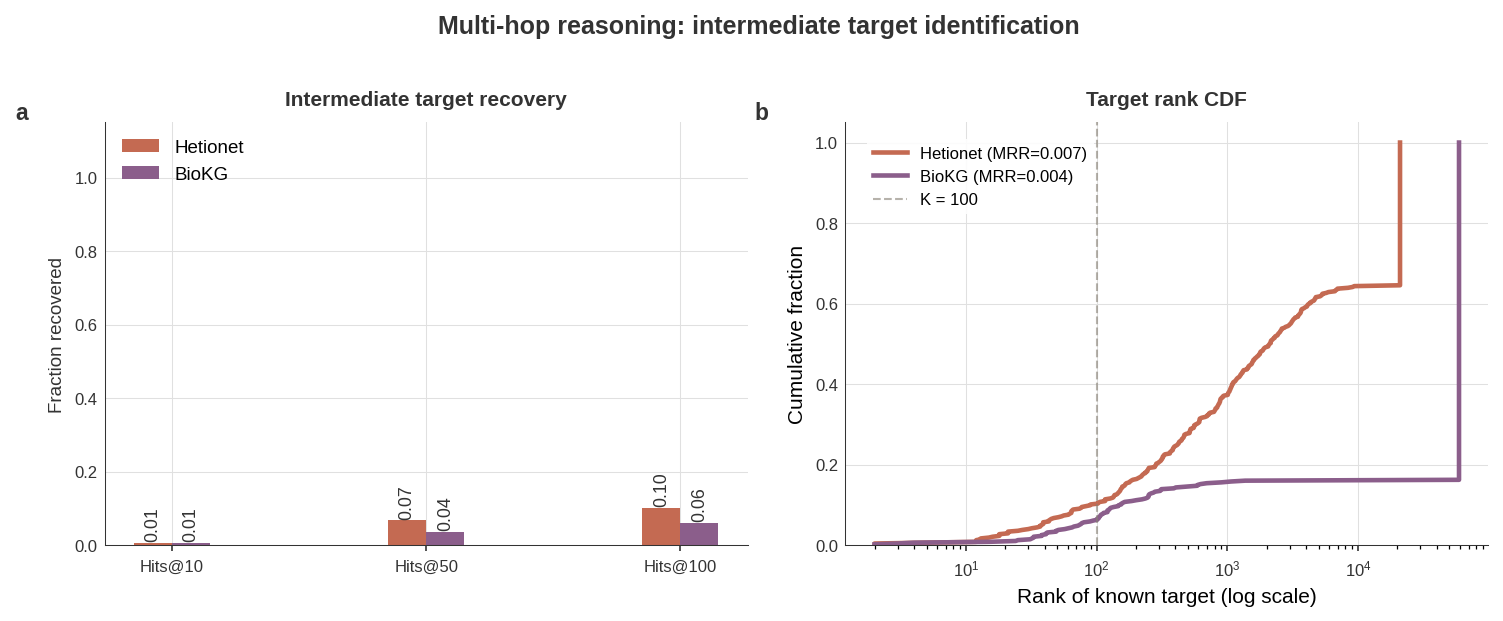

In [23]:
# Multi-hop reasoning: Hits@K and the rank CDF behind it.
out.figure(fig06_multihop(multihop_results), 'multihop_reasoning');


### Checkpoint

## Dimension score

The task performance dimension score combines three sub-metrics:

$$\text{Task Performance} = \frac{1}{3}\left(\text{Link Prediction} + \text{Neighbourhood Retrieval} + \text{Multi-hop Reasoning}\right)$$

**Link prediction** is the AUROC achieved by Adamic-Adar under type-constrained negative sampling, the pre-specified primary heuristic. Adamic-Adar is preferred over Common Neighbors and Jaccard because it down-weights shared neighbours that are high-degree hubs ($\sum_{w \in N(u) \cap N(v)} 1/\log|N(w)|$), making it more biologically motivated: a low-degree shared intermediate node represents more specific structural evidence than a highly connected hub. Results for all three heuristics are stored in `lp_all_heuristics` in the checkpoint and reported in the supplementary table.

**Neighbourhood retrieval** is Recall@100 from a leave-one-out evaluation: for each disease with $\geq 5$ known gene targets, one target is held out and ranked against the full gene pool using Adamic-Adar.

**Multi-hop reasoning** is Hits@100 from intermediate target identification using CTD gold-standard (drug, gene, disease) triplets: all candidate genes are scored as potential intermediates via $\text{AA}(\text{drug}, g) \times \text{AA}(g, \text{disease})$, and the fraction of cases where the known target ranks in the top 100 is reported.

In [24]:
# Scalar results for downstream notebooks, with bootstrap CIs.
#
# Written through `out`, so the checkpoint stem matches the notebook directory
# (06_task_performance.pkl) as it does for every other dimension. It was
# 06_predictive_performance.pkl, the only stem in the panel that did not match
# its folder; notebook 00's filename map is updated to match.

# A missing link-prediction result is a broken run, not a graph that predicts
# perfectly in reverse. AUROC 0.0 is not neutral: 0.5 is chance, so recording a
# failure as 0.0 placed it below every attainable result and ranked it last for a
# reason that is not a property of the graph. Same fallback removed from 04 and 05.
_absent = [n for n in LOADED
           if (n, PRIMARY_HEURISTIC, ANCHOR_STRAT) not in link_results]
if _absent:
    raise RuntimeError(
        f'No {PRIMARY_HEURISTIC} / {ANCHOR_STRAT} link-prediction result for '
        f'{_absent}. Re-run the evaluation rather than scoring these graphs 0.0, '
        f'which reads as a property of the graph instead of a failed computation.')

# 1. Link prediction (type-constrained) Adamic-Adar AUROC
lp_tc_scores = {}
lp_tc_ci = {}  # NEW CI bounds
lp_all_heuristics = {}
for name in LOADED:
    aa_result = link_results[(name, PRIMARY_HEURISTIC, ANCHOR_STRAT)]
    lp_tc_scores[name] = round(float(aa_result['auroc']), 4)
    lp_tc_ci[name] = {
        'auroc_ci_lo': round(aa_result.get('auroc_ci_lo', np.nan), 4),
        'auroc_ci_hi': round(aa_result.get('auroc_ci_hi', np.nan), 4),
        'auprc_ci_lo': round(aa_result.get('auprc_ci_lo', np.nan), 4),
        'auprc_ci_hi': round(aa_result.get('auprc_ci_hi', np.nan), 4),
    }
    lp_all_heuristics[name] = {
        h: (round(float(link_results[(name, h, ANCHOR_STRAT)]['auroc']), 4)
            if (name, h, ANCHOR_STRAT) in link_results else float('nan'))
        for h in SCORERS
    }

print(f'Link prediction — type-constrained AUROC ({PRIMARY_HEURISTIC}, primary):')
for kg, s in lp_tc_scores.items():
    ci = lp_tc_ci[kg]
    print(f'  {kg:12s}: {s:.4f}  95% CI [{ci["auroc_ci_lo"]:.4f}, {ci["auroc_ci_hi"]:.4f}]')

# 2. Neighbourhood retrieval Recall@100
#
# Two failure modes, kept apart. Absent from target_results is a broken run and
# raises. Present with n_evaluated == 0 is a graph that had no answerable query,
# which is NA: it was never asked, so 0.0 would report a floor result for a
# question that was not put. Neither is scored as zero.
_absent = [n for n in LOADED if n not in target_results]
if _absent:
    raise RuntimeError(
        f'No neighbourhood-retrieval result for {_absent}. Re-run rather than '
        f'scoring these graphs 0.0, which reads as a property of the graph '
        f'instead of a failed computation.')

nbhd_scores = {}
for name in LOADED:
    tr = target_results[name]
    nbhd_scores[name] = (round(float(tr['recall@100']), 4)
                         if tr['n_evaluated'] > 0 else np.nan)

print('\nNeighbourhood retrieval, Recall@100:')
for kg in LOADED:
    s  = nbhd_scores[kg]
    tr = target_results[kg]
    if not np.isfinite(s):
        print(f'  {kg:12s}: NA  (no answerable query; '
              f'{tr["n_eligible"]:,} eligible diseases)')
        continue
    ci = nbhd_ci.get(kg, (s, np.nan, np.nan))
    print(f'  {kg:12s}: {s:.4f}  95% CI [{ci[1]:.4f}, {ci[2]:.4f}]  '
          f'n={tr["n_evaluated"]:,} of {tr["n_requested"]:,} requested, '
          f'{tr["n_eligible"]:,} eligible')

# 3. Multi-hop reasoning Hits@100
_absent = [n for n in LOADED if n not in multihop_results]
if _absent:
    raise RuntimeError(
        f'No multi-hop result for {_absent}. Re-run rather than scoring these '
        f'graphs 0.0.')

multihop_scores = {}
for name in LOADED:
    mr = multihop_results[name]
    multihop_scores[name] = (round(float(mr['hits@100']), 4)
                             if mr['n_evaluated'] > 0 else np.nan)

print('\nMulti-hop reasoning, Hits@100:')
for kg in LOADED:
    s  = multihop_scores[kg]
    mr = multihop_results[kg]
    if not np.isfinite(s):
        print(f'  {kg:12s}: NA  (resolves none of the frozen benchmark)')
        continue
    ci = multihop_ci.get(kg, (s, np.nan, np.nan))
    print(f'  {kg:12s}: {s:.4f}  95% CI [{ci[1]:.4f}, {ci[2]:.4f}]  '
          f'n={mr["n_evaluated"]:,}')

# 4. Summary = equal-weighted mean of the available sub-scores, WITH an
#    interval. The three sub-scores are estimated from very different sample
#    sizes, so a bare mean invites a ranking the data does not support: on the
#    two-KG panel the graphs differ by 0.008 with sub-metric CIs an order of
#    magnitude wider than that.
#
#    Method: each bootstrap percentile interval is converted to a standard
#    error under a normal approximation, SE = (hi - lo) / (2 * 1.96). The three
#    tasks are evaluated on disjoint samples (held-out indication pairs, drawn
#    diseases, frozen CTD triples), so their errors are treated as independent
#    and SE(mean) = sqrt(sum SE_i^2) / k. Both are approximations and are
#    labelled as such in the table; they are here to stop a difference being
#    read as real, not to support a significance claim. The permutation test in
#    the link-prediction section is the formal comparison.
_Z = 1.959963985
RESCALE_AUROC = require(params, 'rescale_auroc')


def _scale_auroc(a):
    """Map AUROC onto the 0-to-1 range the other two sub-metrics already use.

    AUROC has a chance floor of 0.5; Recall and Hits have a floor near 0. An
    unweighted mean of the raw values is therefore not unweighted: every graph
    collected ~0.167 of the composite for being at chance, and link prediction
    supplied ~79% of Hetionet's 0.3801 and ~81% of BioKG's 0.3723. Rescaling to
    (AUROC - 0.5) / 0.5 puts all three on a common floor so the mean means what
    it says. Clipped at 0 because below-chance discrimination is not negative
    skill here, it is noise. Raw AUROC remains the reported figure everywhere
    else; only the composite uses this.
    """
    if not np.isfinite(a):
        return np.nan
    return float(np.clip((a - 0.5) / 0.5, 0.0, 1.0)) if RESCALE_AUROC else float(a)


def _se_from_ci(lo, hi):
    """Normal-approximation SE from a percentile bootstrap interval."""
    if lo is None or hi is None or not np.isfinite(lo) or not np.isfinite(hi):
        return np.nan
    return (float(hi) - float(lo)) / (2 * _Z)


# The composite runs on the COMPARABLE forms of all three: rescaled AUROC, and
# the pool-normalised cuts for retrieval and multi-hop. The raw forms
# (AUROC, Recall@100, Hits@100) stay in sub_scores_raw and in every table,
# because they are what the literature reports and what a reader will want to
# compare against other papers.
sub_scores, sub_scores_raw, sub_ci, summary_scores, summary_ci = {}, {}, {}, {}, {}
for name in LOADED:
    lp_raw = lp_tc_scores[name]
    nr_raw = nbhd_scores[name]
    mh_raw = multihop_scores[name]
    _nf = nbhd_frac_ci.get(name, (np.nan, np.nan, np.nan))
    _mf = multihop_frac_ci.get(name, (np.nan, np.nan, np.nan))

    sub_scores_raw[name] = {
        'link_prediction':    lp_raw,
        'nbhd_retrieval':     nr_raw,
        'multihop_reasoning': mh_raw,
    }
    sub_scores[name] = {
        'link_prediction':    round(_scale_auroc(lp_raw), 4),
        'nbhd_retrieval':     round(_nf[0], 4) if np.isfinite(_nf[0]) else np.nan,
        'multihop_reasoning': round(_mf[0], 4) if np.isfinite(_mf[0]) else np.nan,
    }
    # CIs transform with their point estimates: the AUROC interval is rescaled
    # by the same affine map, the other two come from the normalised bootstrap.
    _ci = {
        'link_prediction':    (_scale_auroc(lp_tc_ci[name]['auroc_ci_lo']),
                               _scale_auroc(lp_tc_ci[name]['auroc_ci_hi'])),
        'nbhd_retrieval':     _nf[1:],
        'multihop_reasoning': _mf[1:],
    }
    sub_ci[name] = _ci

    avail = [k for k in sub_scores[name] if np.isfinite(sub_scores[name][k])]
    if not avail:
        summary_scores[name] = np.nan
        summary_ci[name] = (np.nan, np.nan, np.nan, 0)
        continue
    vals = [sub_scores[name][k] for k in avail]
    ses  = [_se_from_ci(*_ci[k]) for k in avail]
    mean = float(np.mean(vals))
    # A sub-metric whose CI is unavailable contributes to the mean but not to
    # the interval, so the interval is suppressed rather than understated.
    se   = (float(np.sqrt(np.sum(np.square(ses)))) / len(avail)
            if all(np.isfinite(ses)) else np.nan)
    summary_scores[name] = round(mean, 4)
    summary_ci[name] = (round(mean, 4),
                        round(mean - _Z * se, 4) if np.isfinite(se) else np.nan,
                        round(mean + _Z * se, 4) if np.isfinite(se) else np.nan,
                        len(avail))

fmt = lambda v: '  NA  ' if not np.isfinite(v) else f'{v:.4f}'
print('\nTask Performance (equal-weighted mean of the comparable sub-metrics):')
print('  comparable = AUROC rescaled from its 0.5 chance floor; retrieval and')
print(f'  multi-hop cut at the top {require(params, "k_fraction"):.1%} of each '
      f'graph\'s own candidate pool.')
for name in LOADED:
    ss, sr = sub_scores[name], sub_scores_raw[name]
    pt, lo, hi, k = summary_ci[name]
    span = (f'  95% CI [{lo:.4f}, {hi:.4f}]' if np.isfinite(lo) else '  CI unavailable')
    note = '' if k == 3 else f'  ({k}/3 sub-metrics scored)'
    print(f'\n  {name:12s}: {fmt(pt)}{span}{note}')
    print(f'    {"":22s}{"raw":>10s}  {"comparable":>10s}')
    for lbl, key, rawlbl in (('link prediction  ', 'link_prediction', 'AUROC'),
                             ('nbhd retrieval   ', 'nbhd_retrieval', 'Recall@100'),
                             ('multihop reason. ', 'multihop_reasoning', 'Hits@100')):
        print(f'    {lbl} {rawlbl:<9s}{fmt(sr[key]):>8s}  {fmt(ss[key]):>10s}')
    # Diagnostic only. The WEIGHTS are equal: each sub-metric enters the mean
    # with coefficient 1/k and that is the intended design. What differs is the
    # LEVEL each metric sits at, so they do not contribute equally to the total
    # even under equal weights. Printed because a reader comparing two graphs
    # should know the mean is mostly tracking link prediction, not because the
    # weighting needs changing. On the raw scale this was partly an artefact of
    # AUROC's 0.5 floor; after the rescale it reflects that discriminating
    # 1:5 positives is simply an easier task than top-0.5% retrieval.
    _av = [v for v in ss.values() if np.isfinite(v)]
    if _av and sum(_av) > 0:
        shares = '  '.join(
            f'{n}={v / sum(_av):.0%}'
            for n, v in ss.items() if np.isfinite(v))
        print(f'    equal weights (1/{len(_av)} each); resulting contribution '
              f'to the total: {shares}')

# Whether the panel is actually separated, stated rather than left to the
# reader of a sorted table. Overlapping intervals are not a formal test, but a
# ranking printed without this line implies a separation that may not exist.
_sep = [n for n in LOADED if np.isfinite(summary_ci[n][1])]
if len(_sep) >= 2:
    print('\nPairwise separation on the dimension score (CI overlap):')
    for a, b in combinations(_sep, 2):
        _, alo, ahi, _ = summary_ci[a]
        _, blo, bhi, _ = summary_ci[b]
        overlap = alo <= bhi and blo <= ahi
        print(f'  {a:12s} vs {b:12s}  '
              f'delta={summary_scores[a] - summary_scores[b]:+.4f}  '
              f'{"intervals overlap, not separated" if overlap else "intervals disjoint"}')

# 5. Serialise and save
link_records = [
    {'kg': k[0], 'heuristic': k[1], 'strategy': k[2],
     **{mk: mv for mk, mv in v.items() if isinstance(mv, (int, float, str)) or mv is None}}
    for k, v in link_results.items()
]

nbhd_scalars = {
    name: {k: v for k, v in tr.items() if k not in ('ranks', 'queries')}
    for name, tr in target_results.items()
}
# Inject CIs into nbhd_scalars
for name in LOADED:
    ci = nbhd_ci.get(name, (np.nan, np.nan, np.nan))
    nbhd_scalars[name]['recall@100_ci_lo'] = ci[1]
    nbhd_scalars[name]['recall@100_ci_hi'] = ci[2]
    cf = nbhd_frac_ci.get(name, (np.nan, np.nan, np.nan))
    nbhd_scalars[name]['recall@frac_ci_lo'] = cf[1]
    nbhd_scalars[name]['recall@frac_ci_hi'] = cf[2]

multihop_scalars = {
    name: {k: v for k, v in mr.items()
           if k not in ('ranks', 'hits', 'hits_frac', 'nonzero_mask')}
    for name, mr in multihop_results.items()
}
# Inject CIs into multihop_scalars
for name in LOADED:
    ci = multihop_ci.get(name, (np.nan, np.nan, np.nan))
    multihop_scalars[name]['hits@100_ci_lo'] = ci[1]
    multihop_scalars[name]['hits@100_ci_hi'] = ci[2]
    cf = multihop_frac_ci.get(name, (np.nan, np.nan, np.nan))
    multihop_scalars[name]['hits@frac_ci_lo'] = cf[1]
    multihop_scalars[name]['hits@frac_ci_hi'] = cf[2]

ckpt = {
    'summary_scores':      summary_scores,
    'sub_scores':          sub_scores,
    'primary_heuristic':   PRIMARY_HEURISTIC,
    'lp_all_heuristics':   lp_all_heuristics,
    'lp_tc_ci':            lp_tc_ci,
    'sub_ci':              sub_ci,
    'sub_scores_raw':      sub_scores_raw,
    'summary_ci':          summary_ci,
    'nbhd_frac_ci':        nbhd_frac_ci,
    'multihop_frac_ci':    multihop_frac_ci,
    'link_records':        link_records,  # now includes CI fields
    'nbhd_scalars':        nbhd_scalars,  # now includes CI fields
    'multihop_scalars':    multihop_scalars,  # now includes CI fields
    'pval_matrix':         pval_matrix.to_dict(),
    # The split and the negatives, so a cross-check with a different scorer
    # grades exactly the pairs Adamic-Adar was graded on. Reconstructing them in
    # a separate script would be reproducible only by coincidence: it would have
    # to re-derive the same RNG streams, the same type constraints and the same
    # pair ordering, and nothing would catch it if one drifted.
    'splits': {n: {'train_pos': kg_splits[n]['train_pos'],
                   'test_pos':  kg_splits[n]['test_pos']} for n in LOADED},
    'negatives': {n: {s_: list(v) for s_, v in kg_negatives[n].items()}
                  for n in LOADED},
    # Everything a different scorer needs to be asked the SAME questions on the
    # other two tasks. Retrieval and multi-hop hide an edge at scoring time,
    # which a trained model cannot do after the fact, so the cross-check has to
    # train with these pairs removed up front. Exported rather than
    # reconstructed for the same reason as the link-prediction split.
    'retrieval_queries':  {n: target_results[n].get('queries', []) for n in LOADED},
    'gene_lists':         {n: list(map(int, kg_gene_lists[n])) for n in LOADED},
    'disease_gene_rels':  {n: kg_disease_gene_rels[n] for n in LOADED},
    'multihop_validation': multihop_validation,
    'multihop_triples': {
        n: [(int(r.drug_idx), int(r.gene_idx), int(r.disease_idx))
            for r in ctd_resolved[n].itertuples(index=False)
            if not (pd.isna(r.drug_idx) or pd.isna(r.gene_idx)
                    or pd.isna(r.disease_idx))]
        for n in LOADED},
}
# Tables go to disk too. link_records and the per-KG scores were previously
# displayed and pickled but never written as CSV, so a number quoted in the
# supplement existed nowhere a reader could recompute it from.
out.table(pd.DataFrame(link_records), 'link_prediction')
# dimension_scores carries its own uncertainty and the count of sub-metrics
# behind it, so the ranking column is never read without them.
out.table(pd.DataFrame([
    {'KG': n,
     'task_performance':          summary_scores[n],
     'task_performance_ci_lo':    summary_ci[n][1],
     'task_performance_ci_hi':    summary_ci[n][2],
     'n_sub_metrics_scored':      summary_ci[n][3],
     # Comparable scale, which is what the composite averages.
     **sub_scores[n],
     # Raw scale, which is what the literature reports. Both are here so the
     # composite can be recomputed from the table and neither has to be
     # back-derived from the other.
     'link_prediction_auroc_raw':  sub_scores_raw[n]['link_prediction'],
     'nbhd_retrieval_recall100':   sub_scores_raw[n]['nbhd_retrieval'],
     'multihop_reasoning_hits100': sub_scores_raw[n]['multihop_reasoning'],
     'k_fraction':                 require(params, 'k_fraction'),
     'nbhd_k_norm':                target_results[n]['k_norm'],
     'multihop_k_norm':            multihop_results[n]['k_norm'],
     'link_prediction_ci_lo':     sub_ci[n]['link_prediction'][0],
     'link_prediction_ci_hi':     sub_ci[n]['link_prediction'][1],
     'nbhd_retrieval_ci_lo':      sub_ci[n]['nbhd_retrieval'][0],
     'nbhd_retrieval_ci_hi':      sub_ci[n]['nbhd_retrieval'][1],
     'multihop_reasoning_ci_lo':  sub_ci[n]['multihop_reasoning'][0],
     'multihop_reasoning_ci_hi':  sub_ci[n]['multihop_reasoning'][1]}
    for n in LOADED if n in summary_scores]), 'dimension_scores')
out.table(pd.DataFrame([{'KG': n, **nbhd_scalars[n]} for n in nbhd_scalars]),
          'neighbourhood_retrieval')
out.table(pd.DataFrame([{'KG': n, **multihop_scalars[n]} for n in multihop_scalars]),
          'multihop_reasoning')
out.checkpoint(ckpt)
# The run summary prints in the LAST output cell, not here: the link-prediction
# heatmap is written further down, so a summary at this point reported 11 files
# when the notebook writes 13.


Link prediction — type-constrained AUROC (Adamic-Adar, primary):
  hetionet    : 0.8984  95% CI [0.8562, 0.9330]
  biokg       : 0.9089  95% CI [0.9042, 0.9133]

Neighbourhood retrieval, Recall@100:
  hetionet    : 0.1405  95% CI [0.0826, 0.2066]  n=121 of 300 requested, 121 eligible
  biokg       : 0.1467  95% CI [0.1100, 0.1900]  n=300 of 300 requested, 2,482 eligible

Multi-hop reasoning, Hits@100:
  hetionet    : 0.1013  95% CI [0.0738, 0.1308]  n=474
  biokg       : 0.0612  95% CI [0.0401, 0.0844]  n=474

Task Performance (equal-weighted mean of the comparable sub-metrics):
  comparable = AUROC rescaled from its 0.5 chance floor; retrieval and
  multi-hop cut at the top 0.5% of each graph's own candidate pool.

  hetionet    : 0.3504  95% CI [0.3160, 0.3847]
                                 raw  comparable
    link prediction   AUROC      0.8984      0.7968
    nbhd retrieval    Recall@100  0.1405      0.1488
    multihop reason.  Hits@100   0.1013      0.1055
    equal weights (1

PosixPath('/home/claude/bib/results/checkpoints/06_task_performance.pkl')

In [25]:
# Figure-data cache: the inputs results/figures can be rebuilt from without
# re-running the analysis, as in notebooks 03 and 04.
#
# The scalar checkpoint deliberately strips the per-query `ranks` arrays, and the
# precision-recall curves were never stored at all, so three of this notebook's
# four figures could not be redrawn from disk. They can now.
_figdata = {
    'link_records': link_records,
    'primary_heuristic': PRIMARY_HEURISTIC,
    'anchor_strategy': ANCHOR_STRAT,
    'pr_curves': {kg: {'baseline': e['baseline'],
                       'curves': {h: (np.asarray(r), np.asarray(pr), float(a))
                                  for h, (r, pr, a) in e['curves'].items()}}
                  for kg, e in pr_curves.items()},
    'target_results': {n: {**{k: v for k, v in t.items() if k != 'ranks'},
                           'ranks': np.asarray(t['ranks'])}
                       for n, t in target_results.items()},
    'multihop_results': {n: {**{k: v for k, v in m.items() if k not in ('ranks', 'hits')},
                             'ranks': np.asarray(m['ranks'])}
                         for n, m in multihop_results.items()},
}
_fd = BASE / 'results' / 'checkpoints' / '06_figdata.pkl'
_fd.parent.mkdir(parents=True, exist_ok=True)
with open(_fd, 'wb') as _f:
    pickle.dump(_figdata, _f)
print('figure-data cache -> 06_figdata.pkl')


figure-data cache -> 06_figdata.pkl


  → Saved: link_prediction_heatmap.pdf / .png  (300 dpi)

06_task_performance: wrote 13 files
  results/checkpoints/06_task_performance.pkl
  results/figures/06_task_performance/link_prediction_heatmap.pdf
  results/figures/06_task_performance/link_prediction_heatmap.png
  results/figures/06_task_performance/link_prediction_pr.pdf
  results/figures/06_task_performance/link_prediction_pr.png
  results/figures/06_task_performance/multihop_reasoning.pdf
  results/figures/06_task_performance/multihop_reasoning.png
  results/figures/06_task_performance/neighbourhood_retrieval.pdf
  results/figures/06_task_performance/neighbourhood_retrieval.png
  results/tables/06_task_performance/dimension_scores.csv
  results/tables/06_task_performance/link_prediction.csv
  results/tables/06_task_performance/multihop_reasoning.csv
  results/tables/06_task_performance/neighbourhood_retrieval.csv


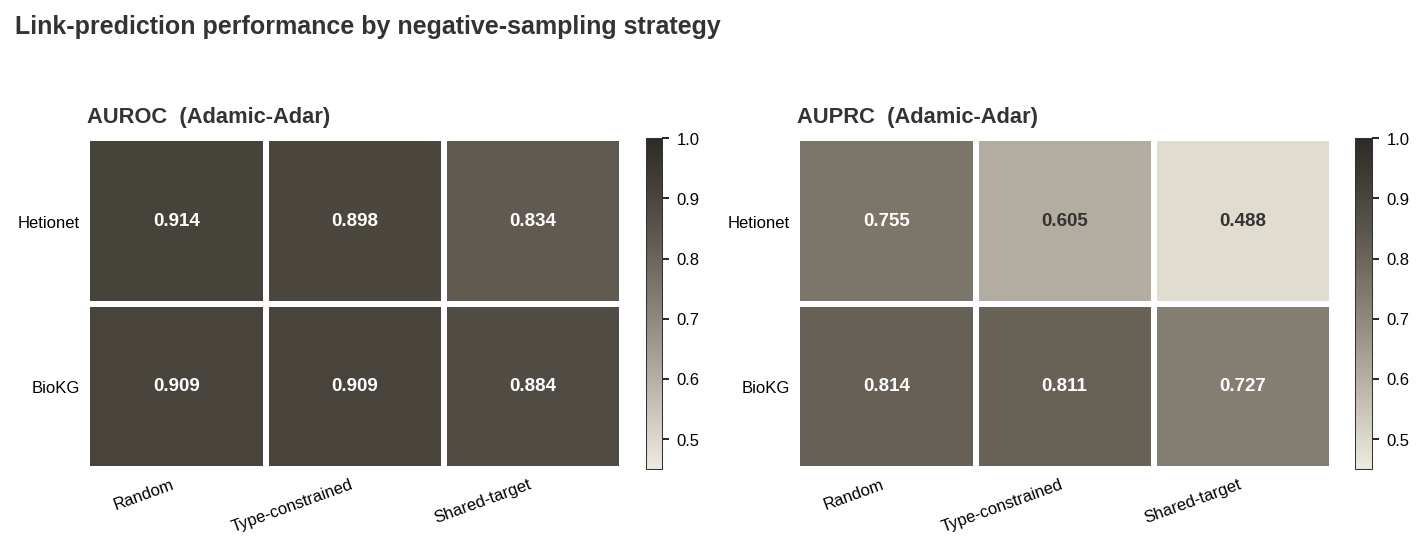

In [26]:
out.figure(fig06_link_heatmap(link_records, PRIMARY_HEURISTIC), 'link_prediction_heatmap');

print()
print(out.summary())


### Statistical methodology

Uncertainty was quantified using the non-parametric percentile bootstrap 
(Efron and Tibshirani, 1993). For each metric and KG, 1,000 bootstrap samples 
were drawn with **stratified resampling**, positives and negatives were resampled 
independently to preserve the class ratio in every bootstrap sample, and the 
2.5th and 97.5th percentiles of the bootstrap distribution define the 95% 
confidence interval. Pairwise differences in AUROC between KGs were assessed 
using a two-sided permutation test (1,000 permutations) with Bonferroni 
correction for $\binom{5}{2} = 10$ pairwise comparisons (family-wise 
$\alpha = 0.05$). For neighbourhood retrieval (Recall@100) and multi-hop 
reasoning (Hits@100), bootstrap CIs were computed by resampling the per-query 
rank vectors.


In [27]:
# Memory cleanup - free state before the next notebook in the pipeline.
_to_free = ['kgs', 'graphs', 'maps', 'preps',
            'kg_pos_pairs', 'kg_entity_sets', 'kg_drug_targets',
            'kg_disease_targets', 'kg_gene_lists', 'kg_disease_degree']
for _v in _to_free:
    try:
        del globals()[_v]
    except KeyError:
        pass
gc.collect()
print('Freed KG state from kernel memory.')

Freed KG state from kernel memory.
